In [2]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
import bokeh.plotting as bok
import os
from numpy.polynomial.polynomial import Polynomial
import pandas as pd
from PyAstronomy import pyasl
from scipy.signal import correlate
from astropy.stats import sigma_clip
from scipy.interpolate import interp1d
from astroscrappy import detect_cosmics
import ast
from astropy.table import Table

%matplotlib inline

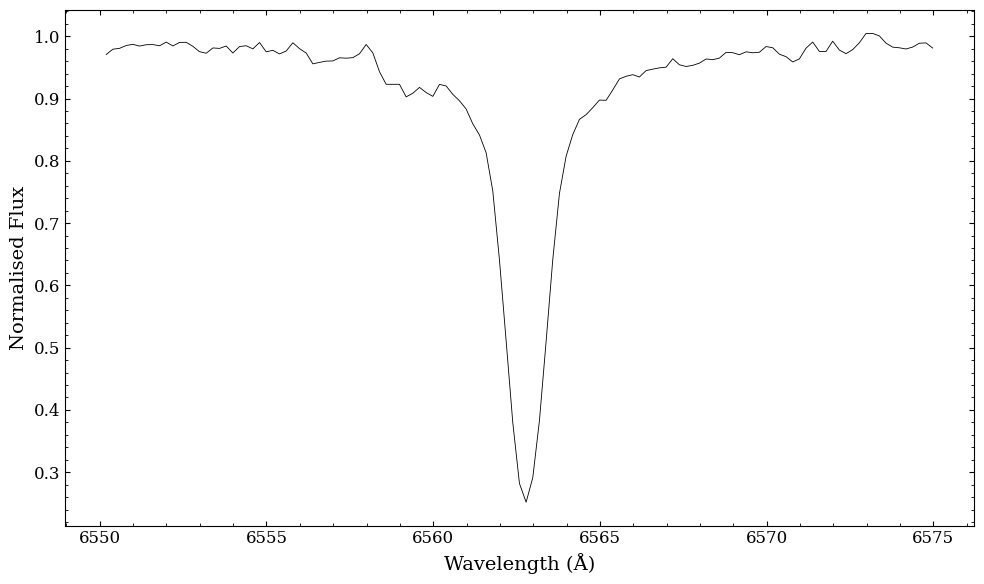

In [11]:
ra_1633_data = Table.read('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/ra_1633-2814_s130/ra_1633-2814_s130_data.fits', hdu=2)

halpha_reg = np.where((ra_1633_data['wave'] > 6550) & (ra_1633_data['wave'] < 6575))

plt.figure(figsize=(10,6))
plt.plot(ra_1633_data['wave'][halpha_reg], ra_1633_data['flux'][halpha_reg], color='black', linewidth=0.6)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()
plt.savefig('ra_1633_halpha.png', dpi=300)

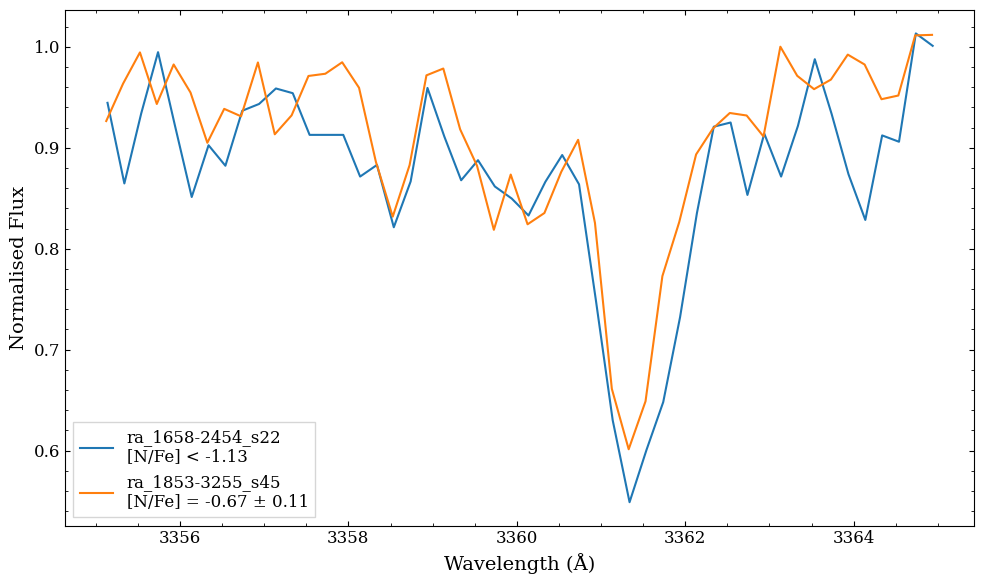

In [12]:
# Loading in the spectra of both ra_1658-2454_s22 and ra_1853-3255_s45
ra_1658_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/ra_1658-2454_s22/N_I/iter_1/N_results.csv')
ra_1658_wave = np.array(ast.literal_eval(ra_1658_df['obs_wave'].to_numpy()[0])[0])
ra_1658_flux = np.array(ast.literal_eval(ra_1658_df['obs_flux'].to_numpy()[0])[0])

ra_1853_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/ra_1853-3255_s45/N_I/iter_1/N_results.csv')
ra_1853_wave = np.array(ast.literal_eval(ra_1853_df['obs_wave'].to_numpy()[0])[0])
ra_1853_flux = np.array(ast.literal_eval(ra_1853_df['obs_flux'].to_numpy()[0])[0])

# Slicing to 3355 - 3365A
wave_slice = np.where((ra_1658_wave > 3355) & (ra_1658_wave < 3365))
ra_1658_wavecut = ra_1658_wave[wave_slice]
ra_1658_fluxcut = ra_1658_flux[wave_slice]
ra_1853_wavecut = ra_1853_wave[wave_slice]
ra_1853_fluxcut = ra_1853_flux[wave_slice]

# Overplotting the NH regions
plt.figure(figsize=(10,6))
plt.plot(ra_1658_wavecut, ra_1658_fluxcut, label="ra_1658-2454_s22\n[N/Fe] < -1.13")
plt.plot(ra_1853_wavecut, ra_1853_fluxcut, label="ra_1853-3255_s45\n[N/Fe] = -0.67 ± 0.11")

plt.legend(fancybox=False)
plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised Flux')
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra1658_vs_ra1853_NH.png', dpi=300, bbox_inches='tight')

### Plotting [N/Fe] spectra on top of each other

In [88]:
def get_synth(star, el, abunds, masks=False):
    
    # Getting the list of synthetic spectra
    path = f'/data/misfit/benlowe/xshooter/korg_data/upper_limits_iter/{star}/{el}/synth_specs/'
    specs = [path + f for f in os.listdir(path) if f.endswith('.csv') and not f.startswith(el)]
    specs.sort()
    # abunds = np.arange(1, -4.01, -0.01)
    
    # Loading in the chisquare values
    chi_path = f'/data/misfit/benlowe/xshooter/korg_data/upper_limits_iter/{star}/{el}/chisqrs.csv'
    chi_df = pd.read_csv(chi_path)
    
    # Taking the minimum chisq value and the corresponding abundance
    min_chi = chi_df['chisq_obs'].min()
    min_abund = chi_df.loc[chi_df['chisq_obs'] == min_chi, 'xfe'].values[0]

    # Loading in the observed spectra (all the same, so will take the first entry)
    obs_df = pd.read_csv(specs[0])
    obs_flux = obs_df['obs_flux'].to_numpy()
    obs_flux_err = obs_df['obs_flux_err'].to_numpy()
    obs_wave = obs_df['obs_wave'].to_numpy()
    
    if el == 'C_I':
        c_reg = np.where((obs_wave >= 4285) & (obs_wave <= 4317))
        obs_flux = obs_flux[c_reg]
        obs_flux_err = obs_flux_err[c_reg]
        obs_wave = obs_wave[c_reg]

    # Loading in the empty spectra
    empty_path = f'/data/misfit/benlowe/xshooter/korg_data/upper_limits_iter/{star}/{el}/empty_specs/'
    empty_specs = [empty_path + f for f in os.listdir(empty_path) if f.endswith('.csv') and not f.startswith(el)]
    empty_df = pd.read_csv(empty_specs[0])
    empty_flux = empty_df['empty_flux'].to_numpy()
    empty_wave = empty_df['empty_wave'].to_numpy()
    
    if el == 'C_I':
        c_reg = np.where((empty_wave >= 4285) & (empty_wave <= 4317))
        empty_flux = empty_flux[c_reg]
        empty_wave = empty_wave[c_reg]

    # Loading in the synthetic spectra
    synth_all = []
    synth_min = []
    for f in specs:
        
        # Getting the synthetic specra for our desired abudnances
        try:
            synth_abund = float((f.split('/')[-1]).split('_')[0])
        except ValueError:
            continue
        if synth_abund in abunds:
            synth_df = pd.read_csv(f)
            synth_flux = synth_df['synth_flux'].to_numpy()
            synth_wave = synth_df['synth_wave'].to_numpy()
            
            if el == 'C_I':
                c_reg = np.where((synth_wave >= 4285) & (synth_wave <= 4317))
                synth_flux = synth_flux[c_reg]
                synth_wave = synth_wave[c_reg]
            
            synth_dict = {'abund': synth_abund, 'wave': synth_wave, 'flux': synth_flux}
            synth_all.append(synth_dict)
            
        # # Getting the synthetic spectra for the minimum abundance
        # if synth_abund == -0.74:
        #     synth_df = pd.read_csv(f)
        #     synth_flux = synth_df['synth_flux'].values
        #     synth_wave = synth_df['synth_wave'].values
            
        #     synth_dict = {'abund': min_abund, 'wave': synth_wave, 'flux': synth_flux}
        #     synth_min.append(synth_dict)
            
    synth_all_df = pd.DataFrame(synth_all)
    # synth_min_df = pd.DataFrame(synth_min)
    synth_all_df = synth_all_df.sort_values(by='abund')

    # synth_df = pd.read_csv(f'/data/misfit/benlowe/xshooter/korg_data/upper_limits_iter/{star}/{el}/synth_specs/{min_abund}_spec.csv')
    # synth_all_df = pd.DataFrame({'abund': [min_abund], 'wave': [synth_df['synth_wave'].values], 'flux': [synth_df['synth_flux'].values]})

    # display(synth_all_df)
    
    # Plotting
    plt.figure(figsize=(10,6))

    # Plotting the observed dataset
    plt.plot(obs_wave, obs_flux, color='black', label='Observed', linewidth=1.5)
    plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', color='grey', alpha=0.5, markersize=2)

    # Plotting the empty dataset
    plt.plot(empty_wave, empty_flux, color='black', label='Empty', linestyle='--', linewidth=1.5)

    # Plotting the synthetic dataset
    # print(star)
    for i in range(len(synth_all_df)):
        print(synth_all_df['abund'][i])
        plt.plot(synth_all_df['wave'][i], synth_all_df['flux'][i], alpha=1, linewidth=0.4) # label=f"[N/Fe] = {synth_all_df['abund'][i]}"
        
    # plt.plot(synth_min_df['wave'][0], synth_min_df['flux'][0], label=f"[N/Fe] = -0.74", linewidth=1.5)
        
    # masks = [(3359, 3360.5)]
    ymin, ymax = plt.gca().get_ylim()
    if masks:
        for start, end in masks:
            fill_range = (obs_wave >= start) & (obs_wave <= end)
            plt.fill_between(obs_wave[fill_range], y1=ymin, y2=ymax, color="grey", alpha=0.5)
    # for start, end in masks:
    #     fill_range = (obs_wave >= start) & (obs_wave <= end)
    #     plt.fill_between(obs_wave[fill_range], y1=0, y2=1.05, color="grey", alpha=0.5)

    plt.legend(fancybox=False)
    plt.xlabel('Wavelength (Å)')
    plt.ylabel('Normalised Flux')
    # plt.ylim(0, 1.05)
    plt.title(f'{star}')
    plt.tight_layout()

    # plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1658-2454_s22_N_synths_v5.png', dpi=300, bbox_inches='tight')

#### For NH

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


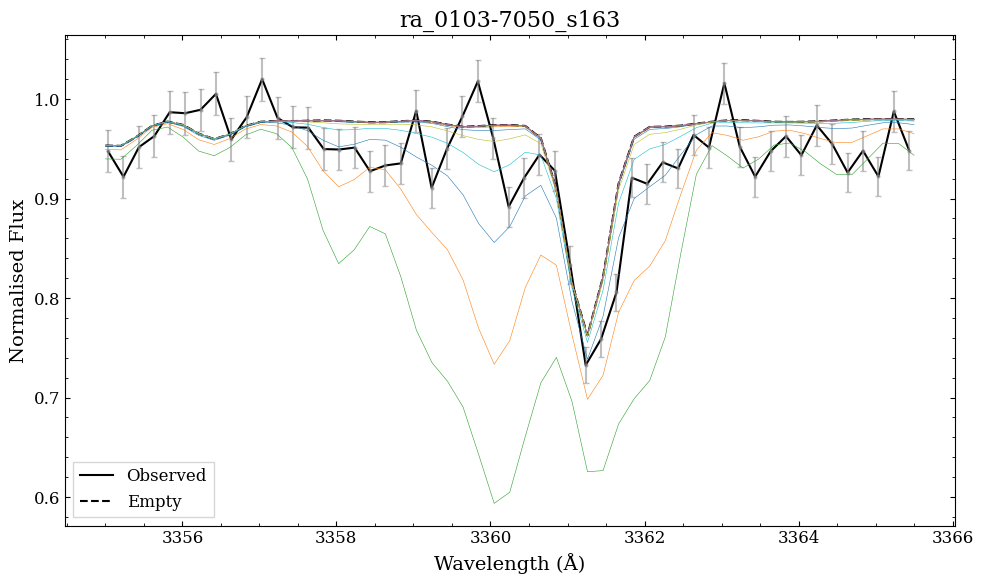

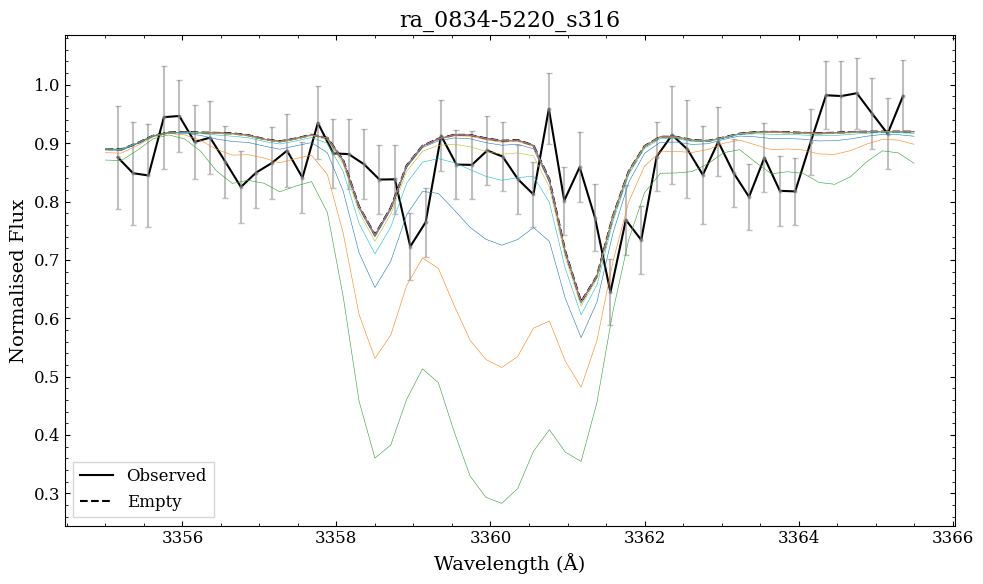

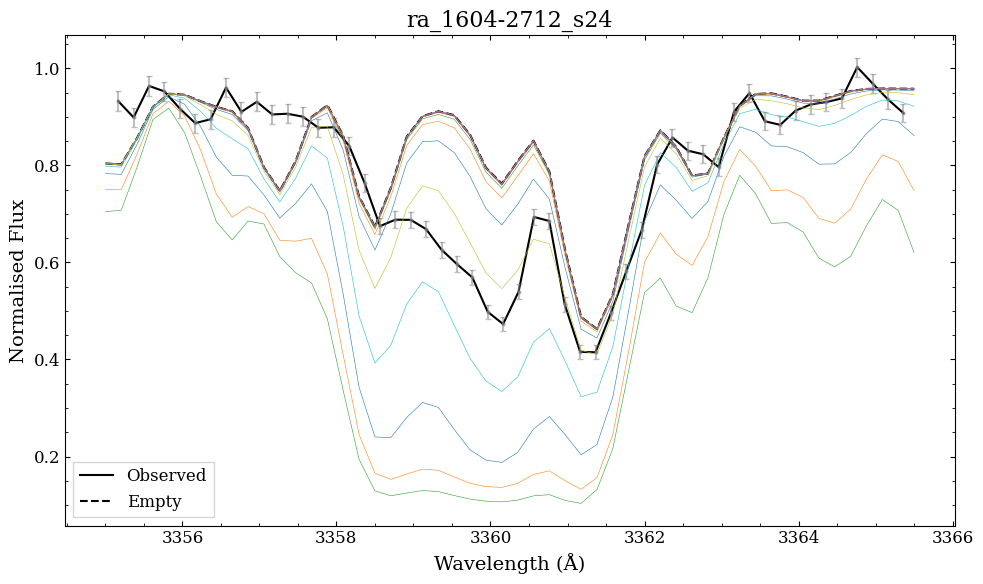

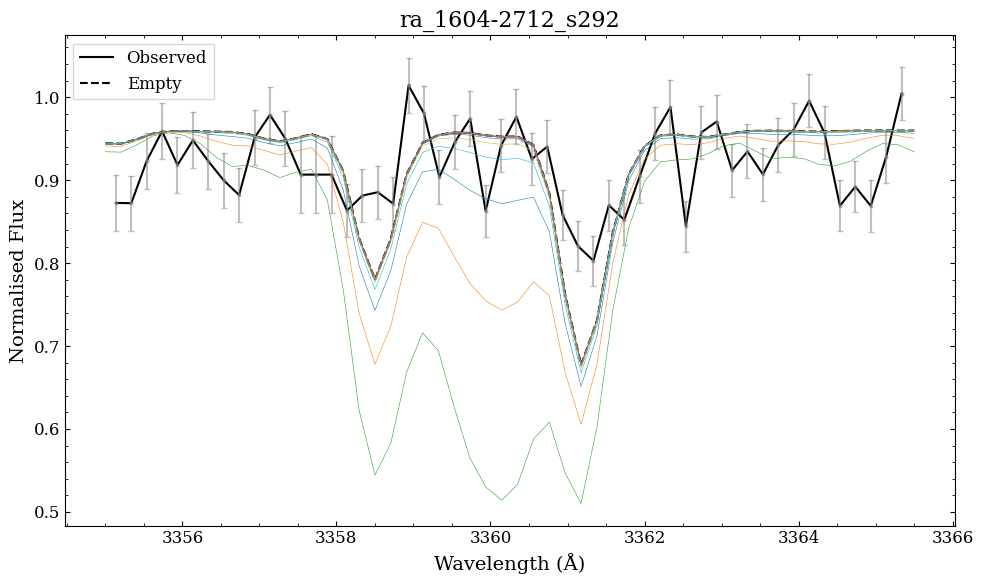

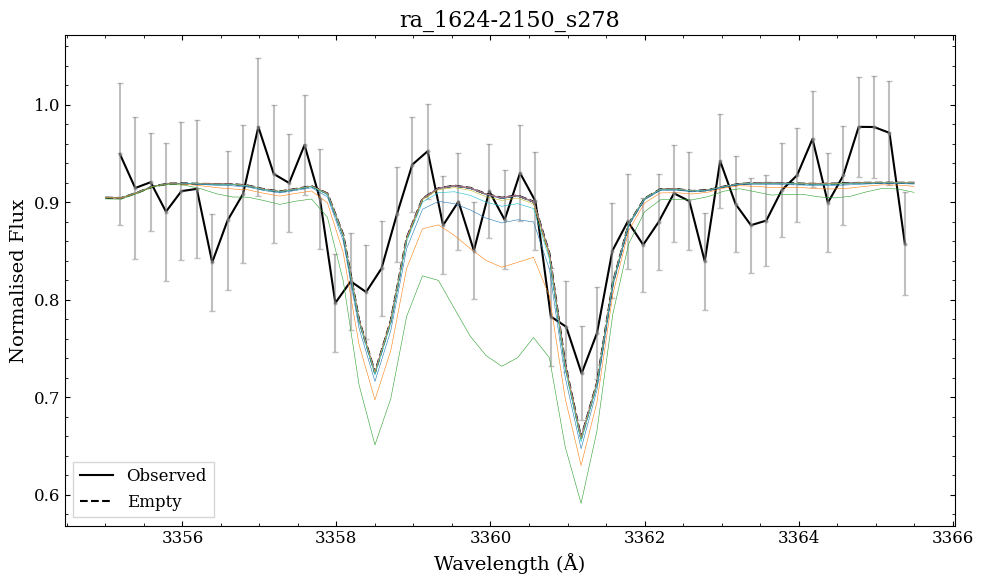

...

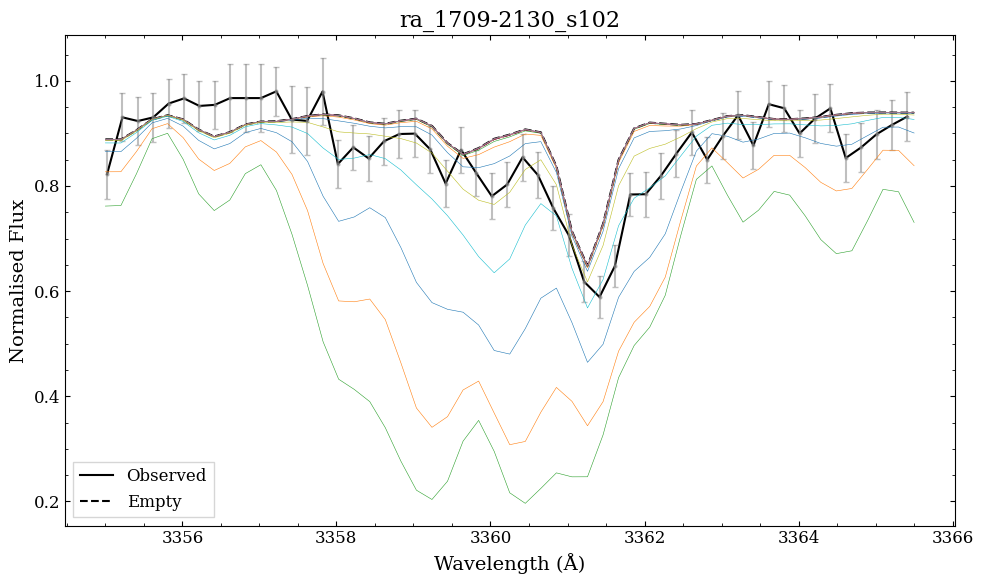

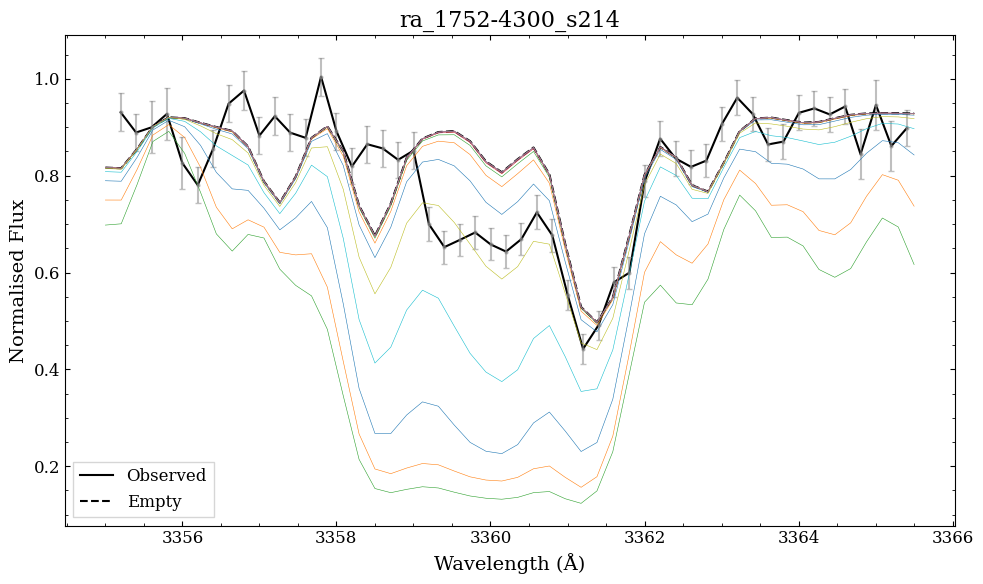

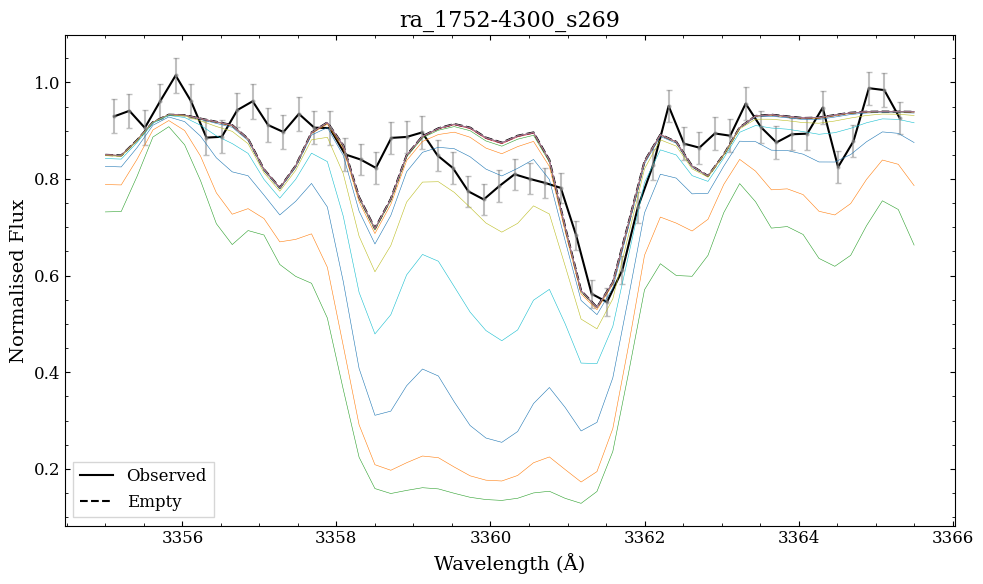

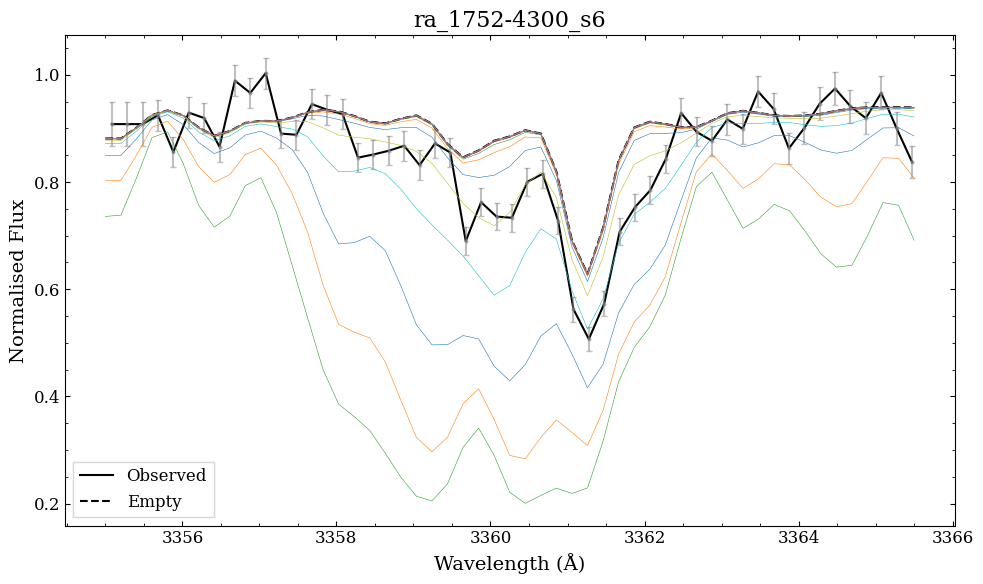

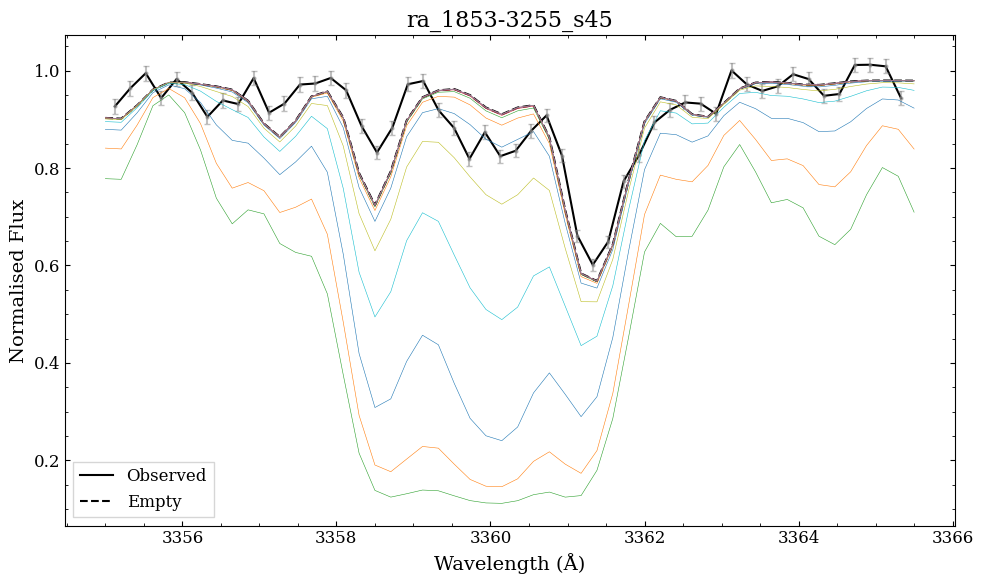

In [60]:
# N_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278', 
#            'ra_1633-2814_s284', 'ra_1648-0653_s38', 'ra_1658-2454_s22', 'ra_1659-2154_s114']
# N_stars = ['ra_1658-2454_s22']
N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/') if s.startswith('ra_')]

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in N_stars:
    get_synth(star, "N_I", abunds)

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


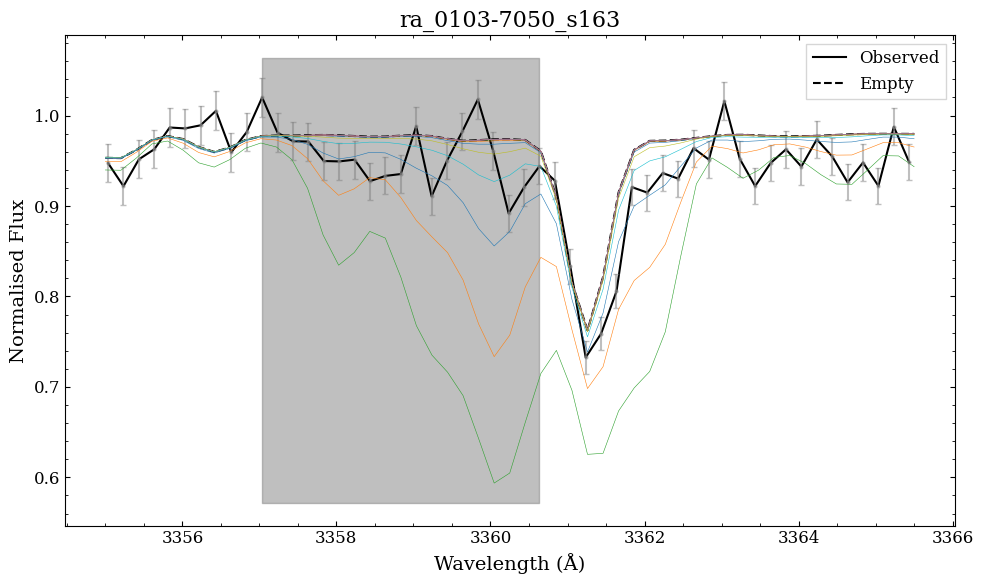

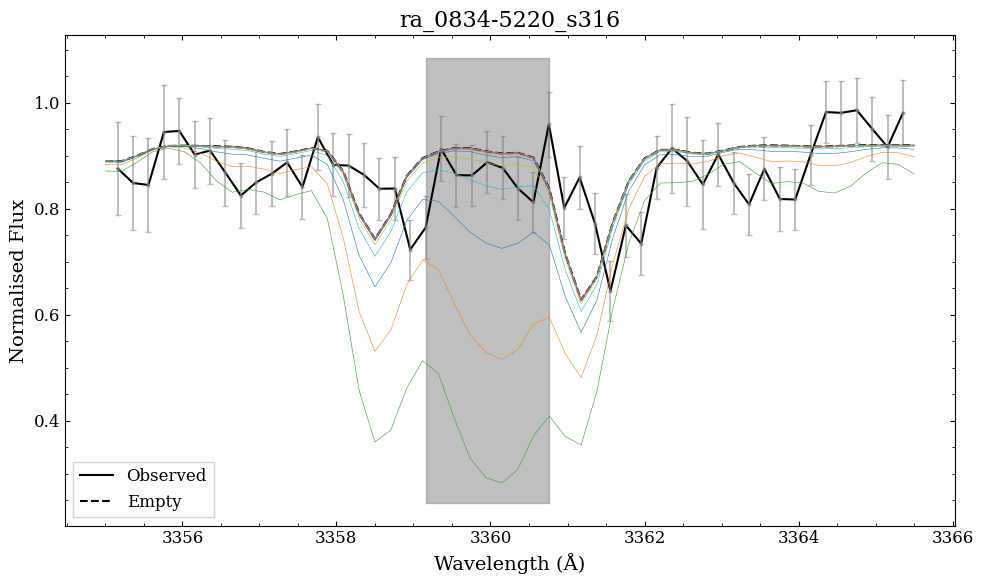

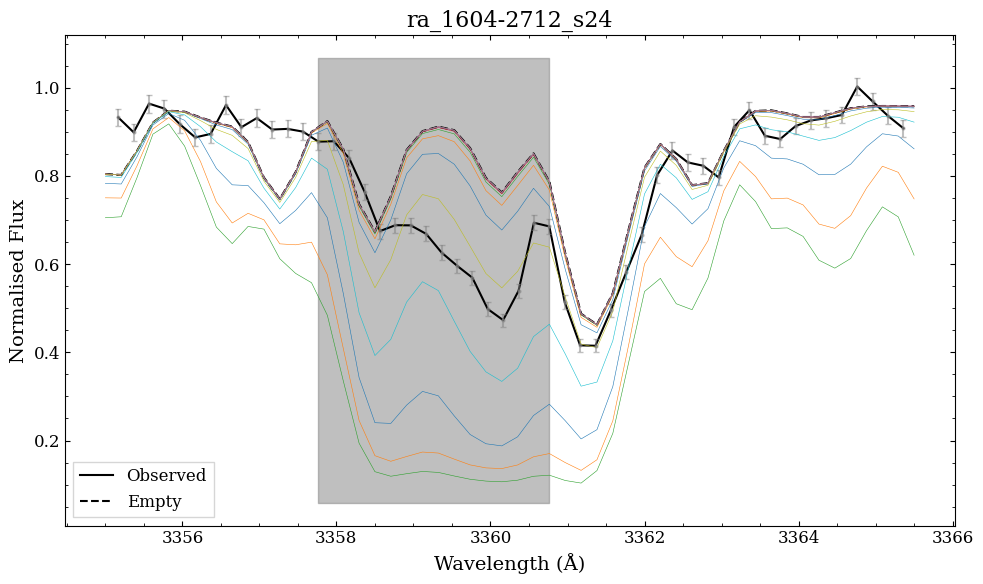

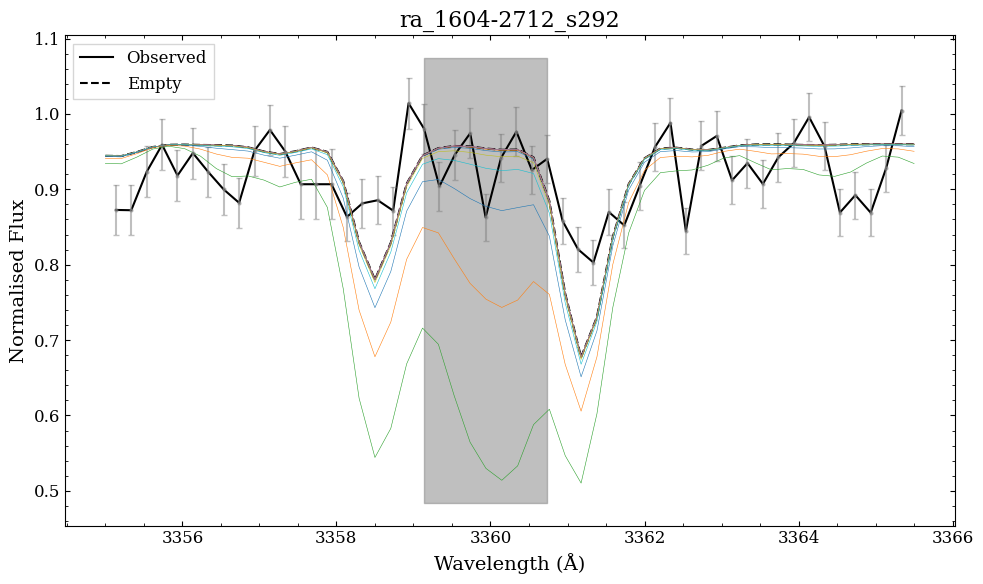

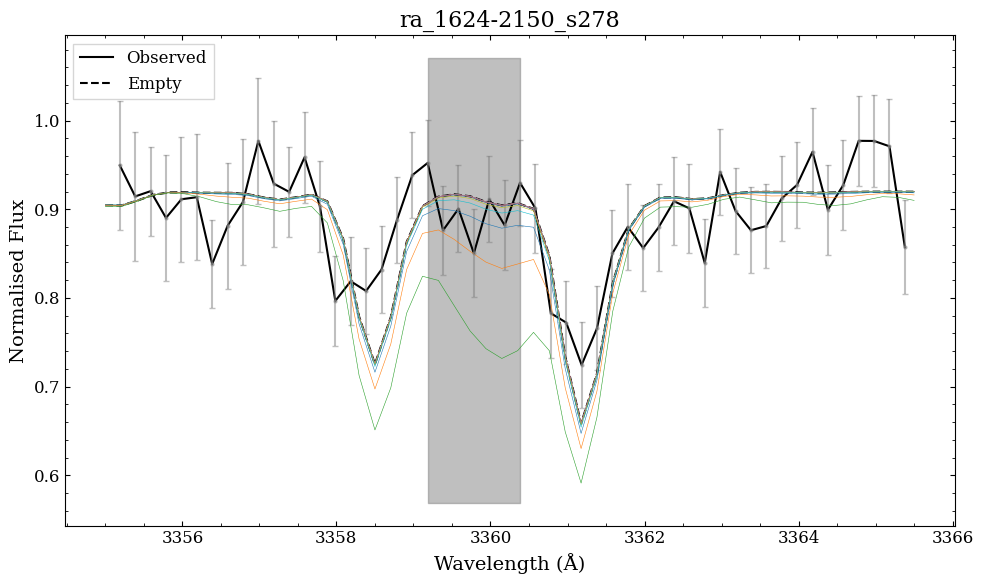

...

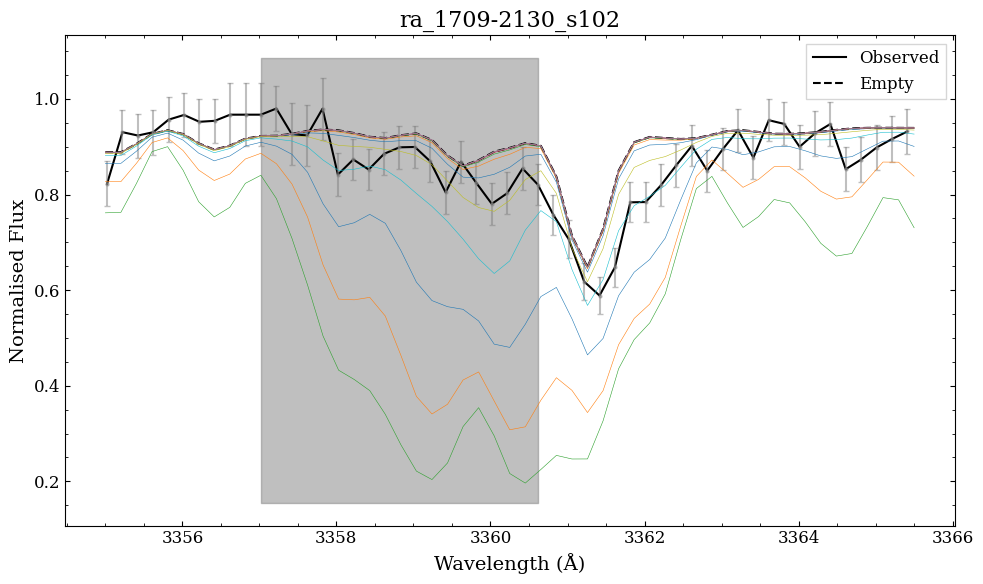

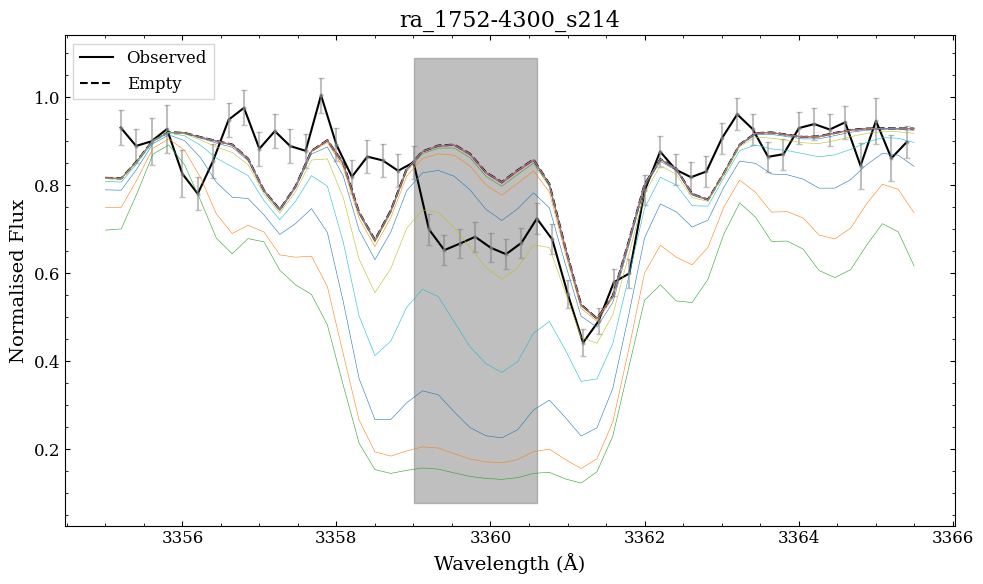

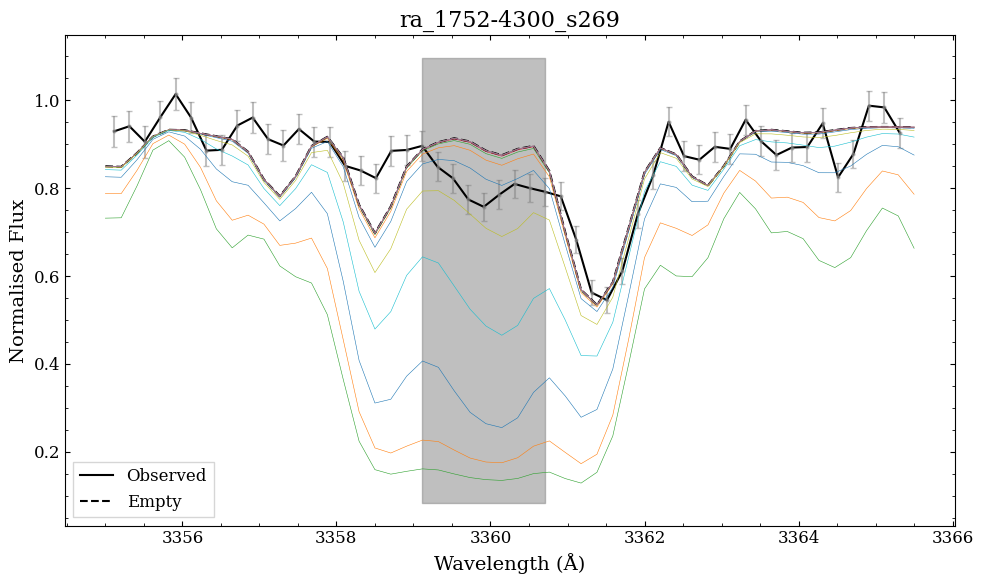

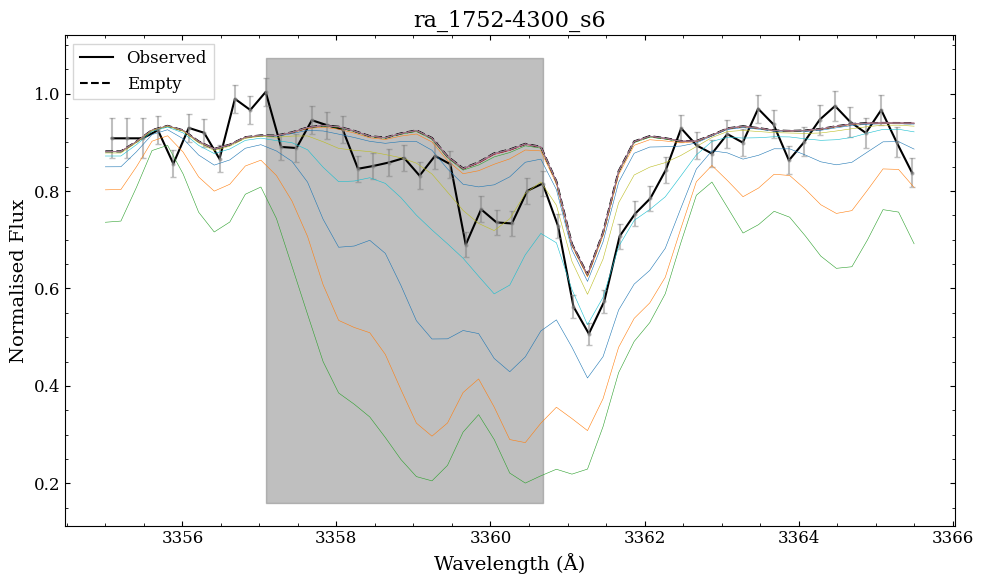

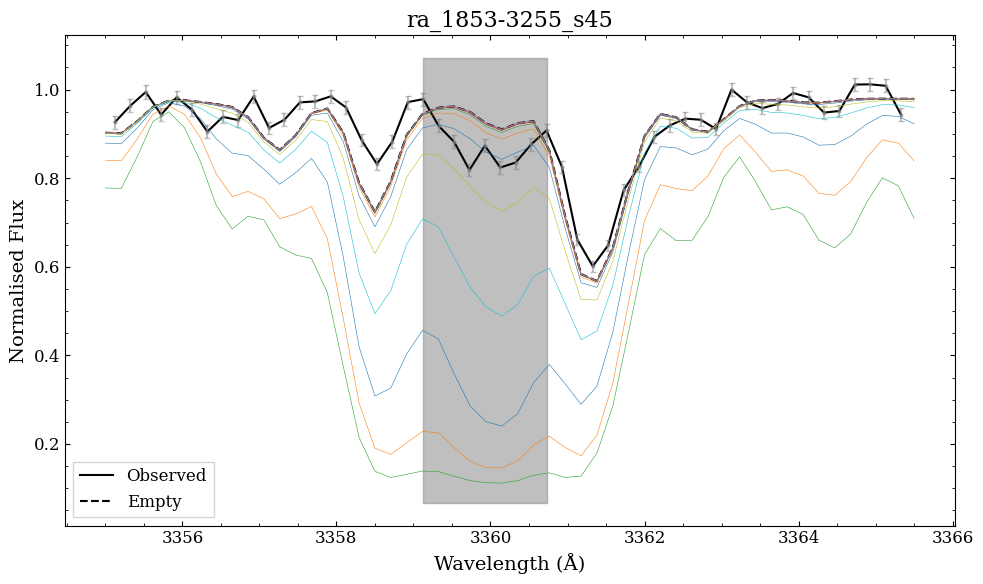

In [78]:
# N_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278', 
#            'ra_1633-2814_s284', 'ra_1648-0653_s38', 'ra_1658-2454_s22', 'ra_1659-2154_s114']
# N_stars = ['ra_1658-2454_s22']
N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/') if s.startswith('ra_')]

# Loading in the masks
masks_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/nh_ch_masks.csv')

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in N_stars:
    
    # Extracting the mask for the star
    star_maskmin = masks_df.loc[masks_df['star_id'] == star, 'nh_maskmin'].values[0]
    star_maskmax = masks_df.loc[masks_df['star_id'] == star, 'nh_maskmax'].values[0]
    star_mask = [(star_maskmin, star_maskmax)]

    get_synth(star, "N_I", abunds, star_mask)

#### For CH

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


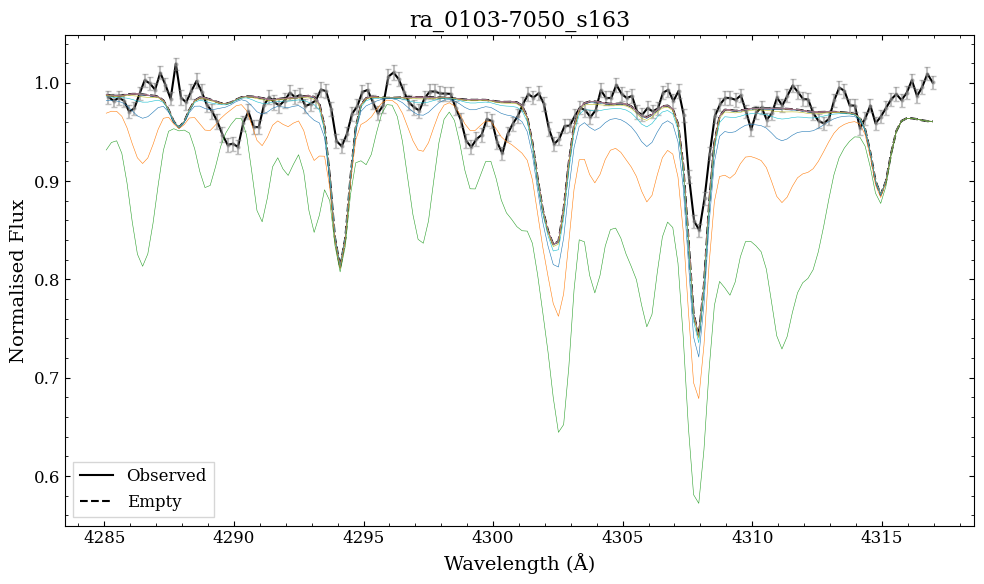

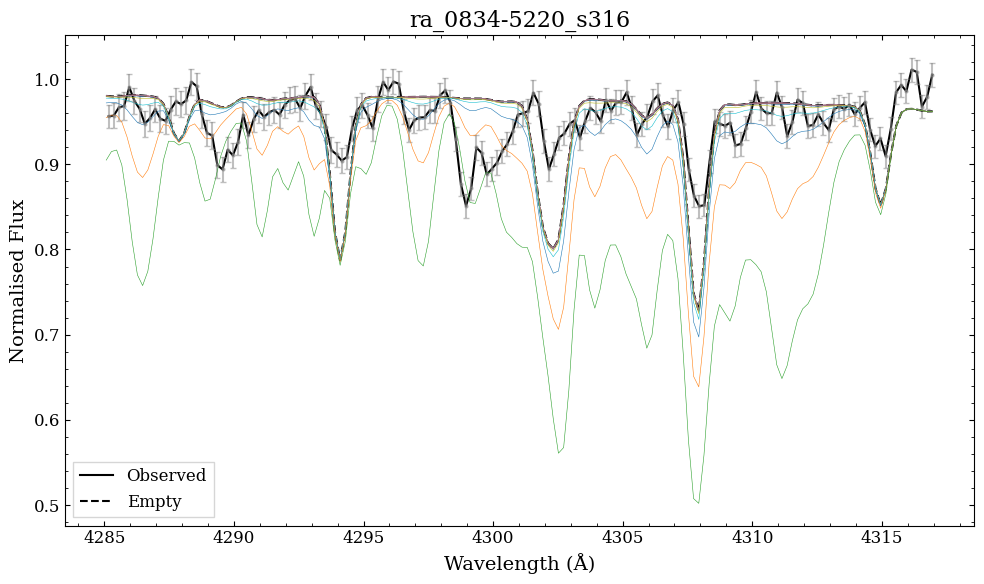

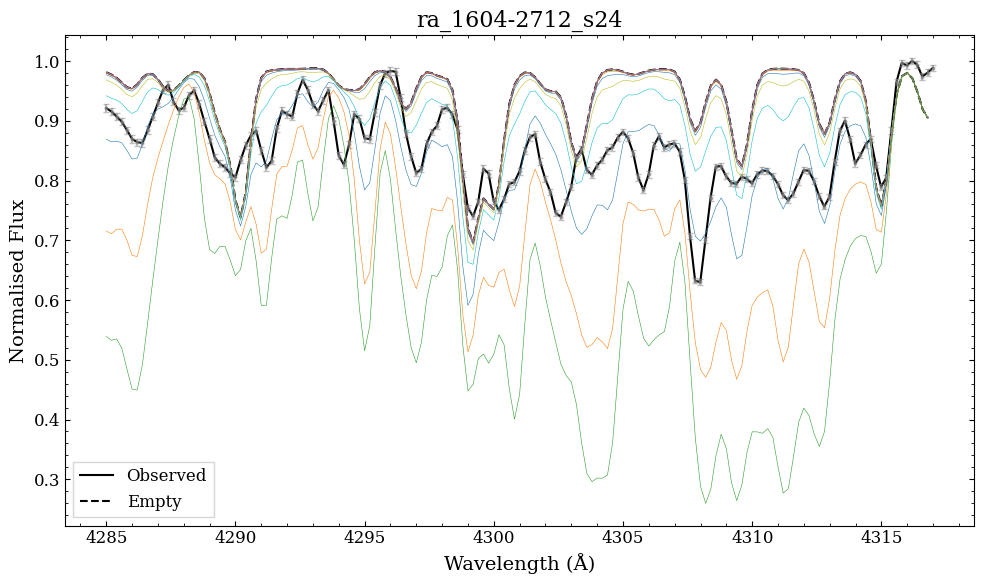

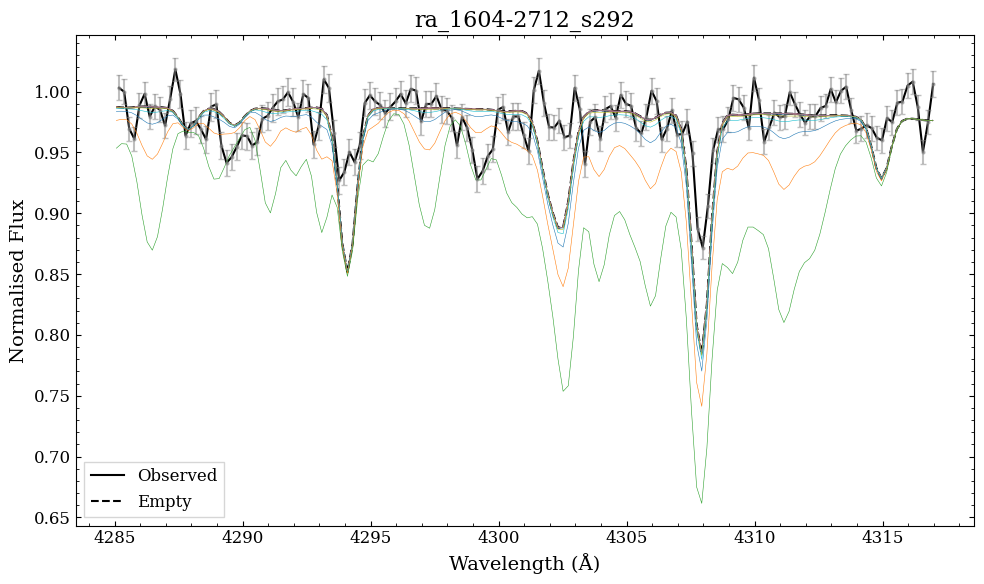

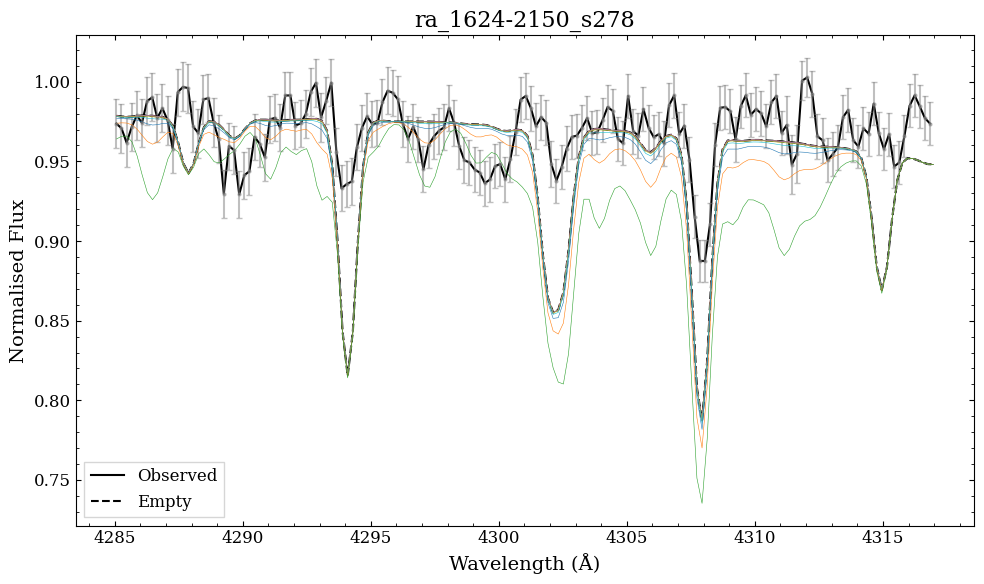

...

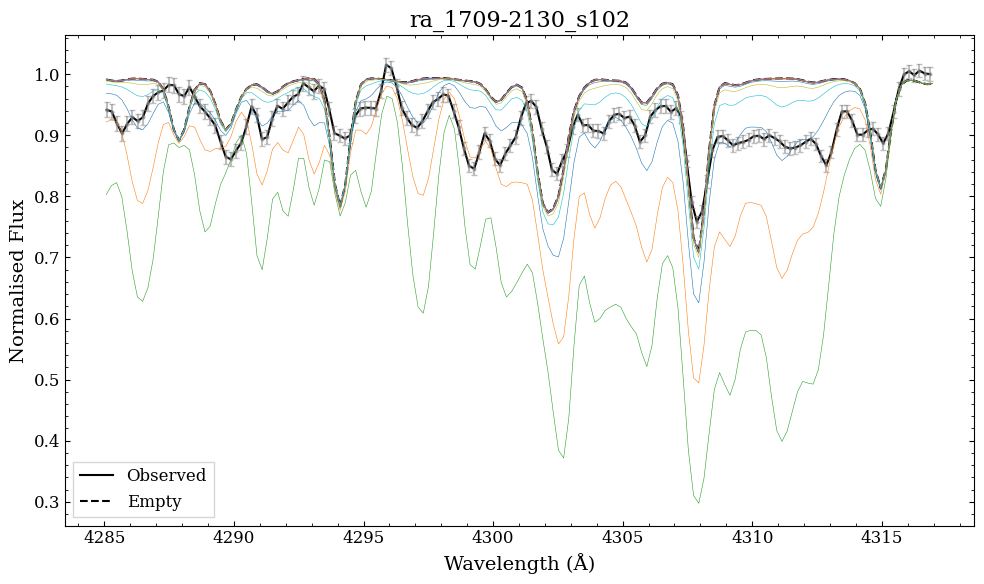

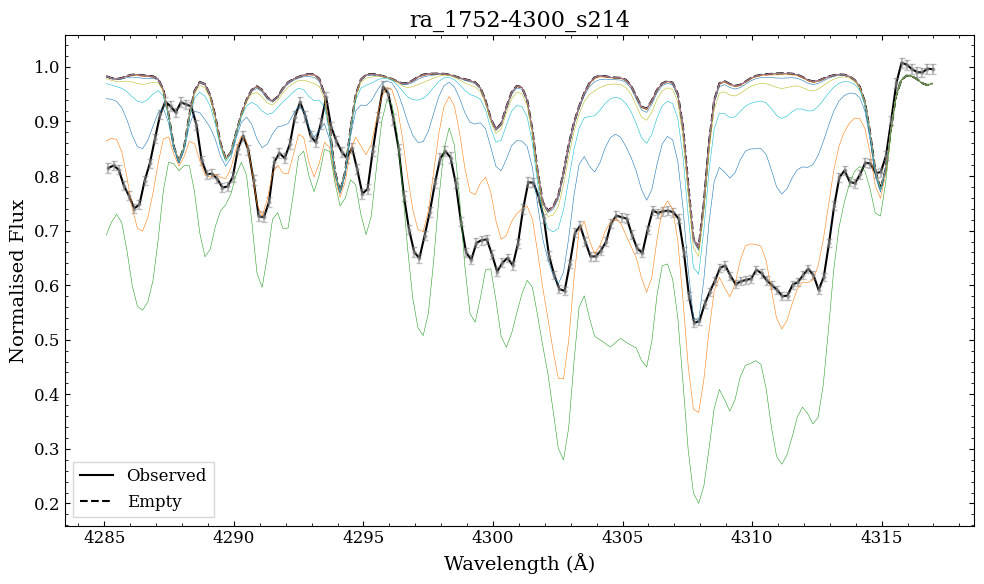

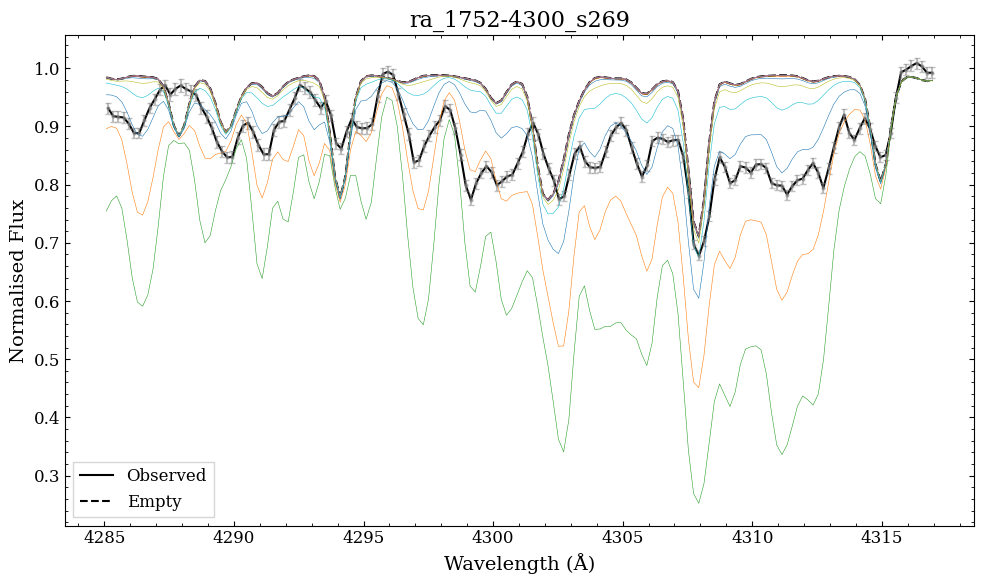

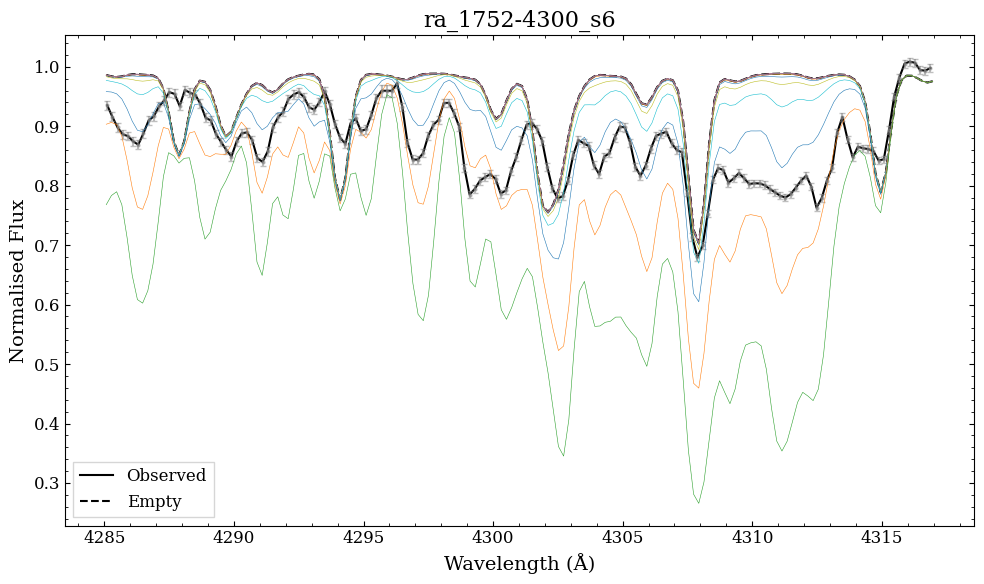

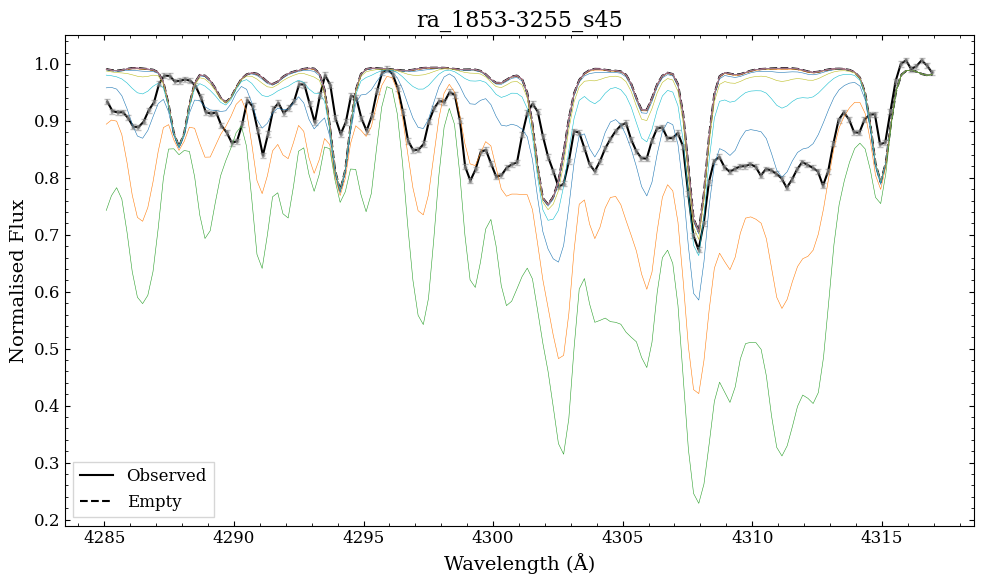

In [89]:
# N_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278', 
#            'ra_1633-2814_s284', 'ra_1648-0653_s38', 'ra_1658-2454_s22', 'ra_1659-2154_s114']
# N_stars = ['ra_1658-2454_s22']
C_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/') if s.startswith('ra_')]

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in C_stars:
    get_synth(star, "C_I", abunds)

### Another idea: subtract all subsequent synthetic spectra, and check when the difference passes a threshold

-3.5
1.394186939543983e-07
-3.0
4.405612310395038e-07
-2.5
5.258480700059021e-07
-2.0
-1.7308086872588734e-05
-1.5
-7.79509914375857e-05
-1.0
-0.0002734212940459041
-0.5
-0.0009103202080347248
0.0
-0.0028364227612536082
0.5
-0.008563347318082946
1.0
-0.023537178815094477
1.5
-0.05600031167643987
2.0
-0.11090039602451575
-3.5
9.40929393225329e-08
-3.0
2.9733981293373216e-07
-2.5
-7.439901563191733e-06
-2.0
-3.6366241686759565e-05
-1.5
-0.00015269532907806366
-1.0
-0.0005120287009600783
-0.5
-0.0016205117082394177
0.0
-0.004974734057269072
0.5
-0.014961583947639174
1.0
-0.04118432216958146
1.5
-0.09690957115360663
2.0
-0.18020512603896105
-3.5
6.166405262263676e-08
-3.0
1.948630315717903e-07
-2.5
6.148575842656302e-07
-2.0
-5.9754994175756145e-06
-1.5
-4.3907085574187776e-05
-1.0
-0.0001799583559688904
-0.5
-0.0006037357411667183
0.0
-0.001955459886128247
0.5
-0.0059601334490360985
1.0
-0.01784899487638812
1.5
-0.048367530933620104
2.0
-0.11097446376984424
-3.5
5.476260700892483e-08
-3.0

-3.5
3.9018765409457715e-09
-3.0
1.2349356447303089e-08
-2.5
3.9155509285638134e-08
-2.0
1.247904598377155e-07
-1.5
-3.4372530066222064e-05
-1.0
-0.00015500162902345858
-0.5
-0.0005381912362080817
0.0
-0.0017358923726207476
0.5
-0.005326897819123523
1.0
-0.015515671686126399
1.5
-0.04250569666881547
2.0
-0.09555213551790835
-3.5
9.558441484016717e-08
-3.0
3.0205716706273077e-07
-2.5
9.531230812292488e-07
-2.0
-1.6467051838442437e-05
-1.5
-7.78983909095665e-05
-1.0
-0.0002733226249799403
-0.5
-0.0009021605718201886
0.0
-0.0027608669527988514
0.5
-0.008439965233468797
1.0
-0.0233734190902298
1.5
-0.05639471111407746
2.0
-0.1134686731504501
-3.5
3.1775851789027046e-07
-3.0
-7.256648054541796e-05
-2.5
-0.0002949523236258676
-2.0
-0.001035869312732194
-1.5
-0.003348424304008857
-1.0
-0.010411296271134326
-0.5
-0.03072725514415509
0.0
-0.07873469302681259
0.5
-0.1658170011224762
1.0
-0.2583976951506894
1.5
-0.33560911877425575
2.0
-0.3881308583418708
-3.5
3.352313383937659e-08
-3.0
1.0593968

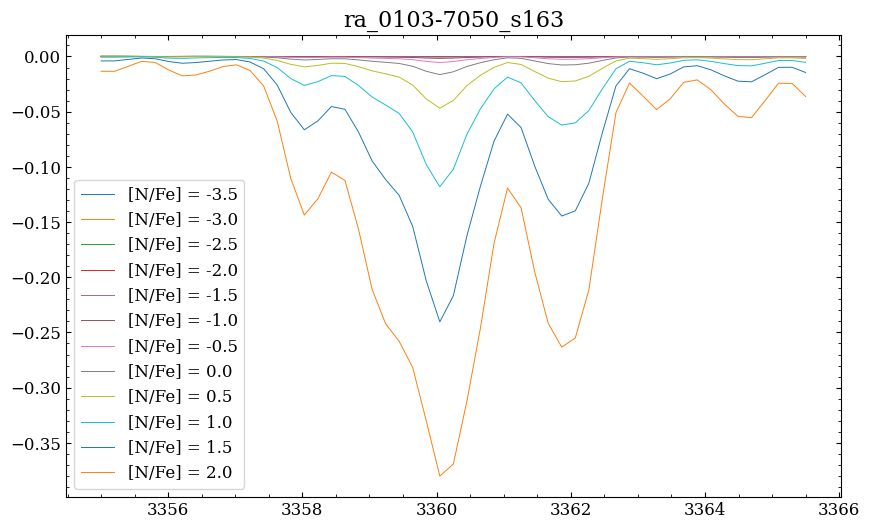

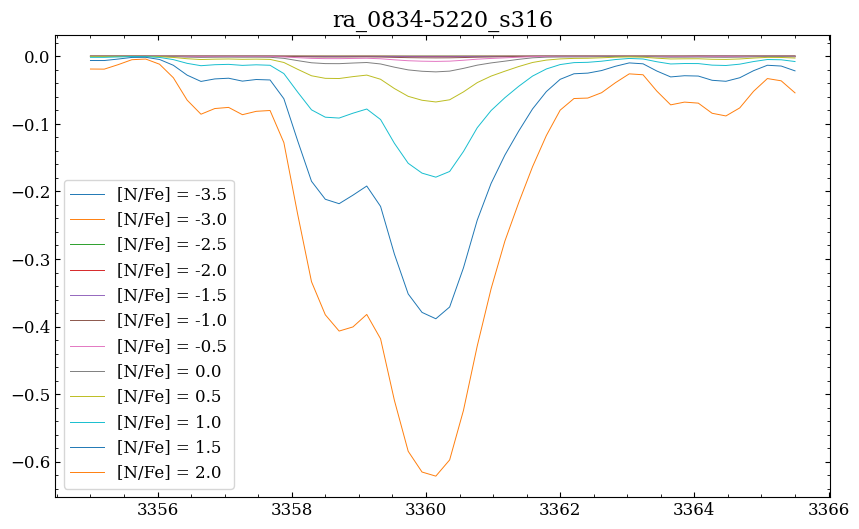

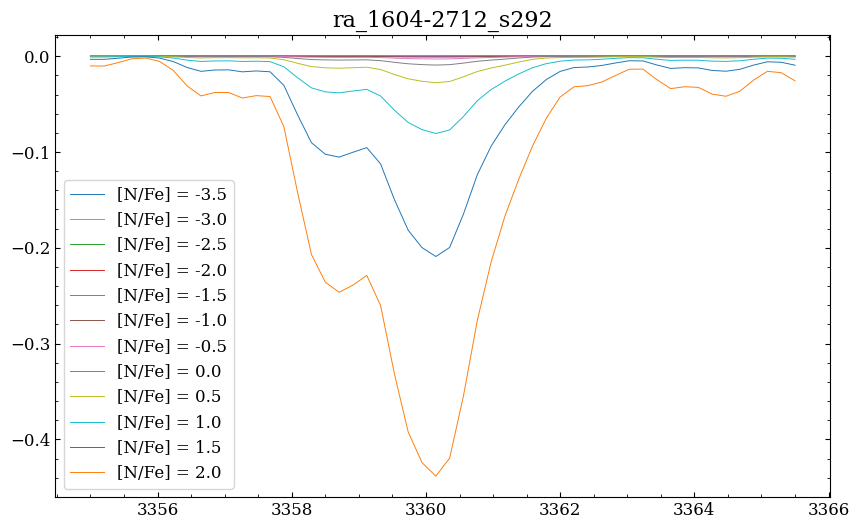

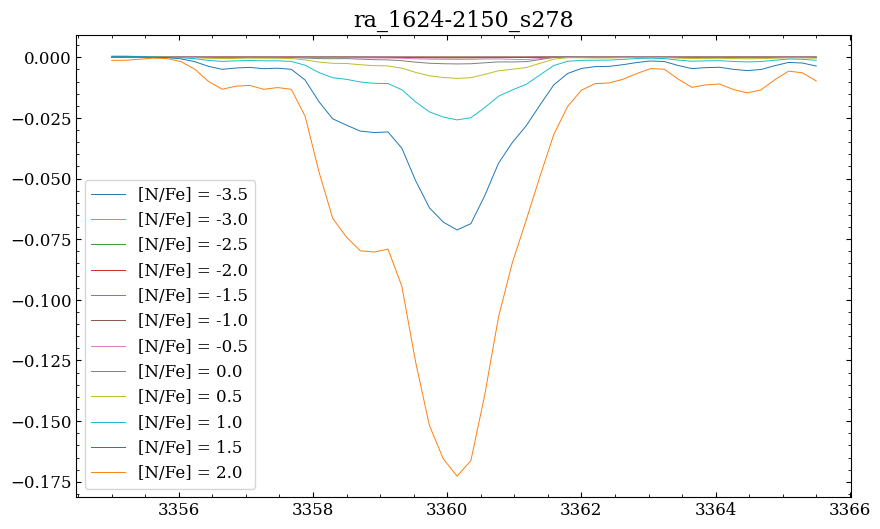

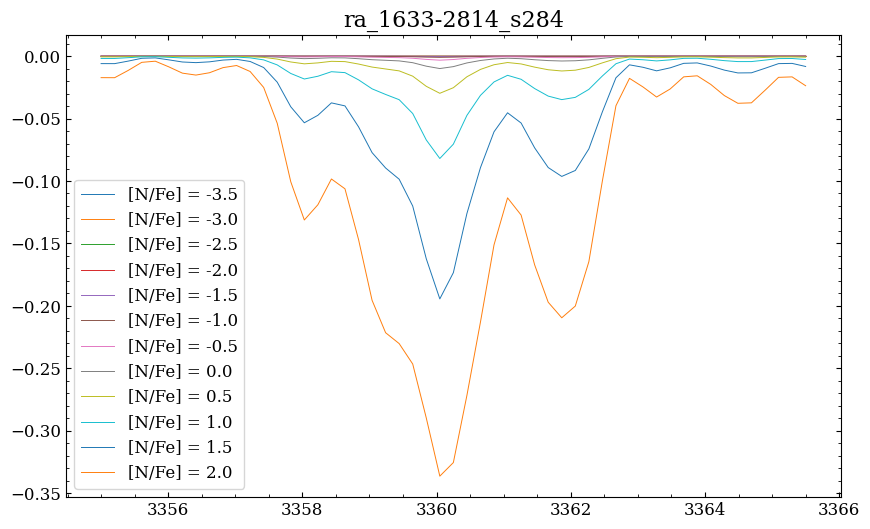

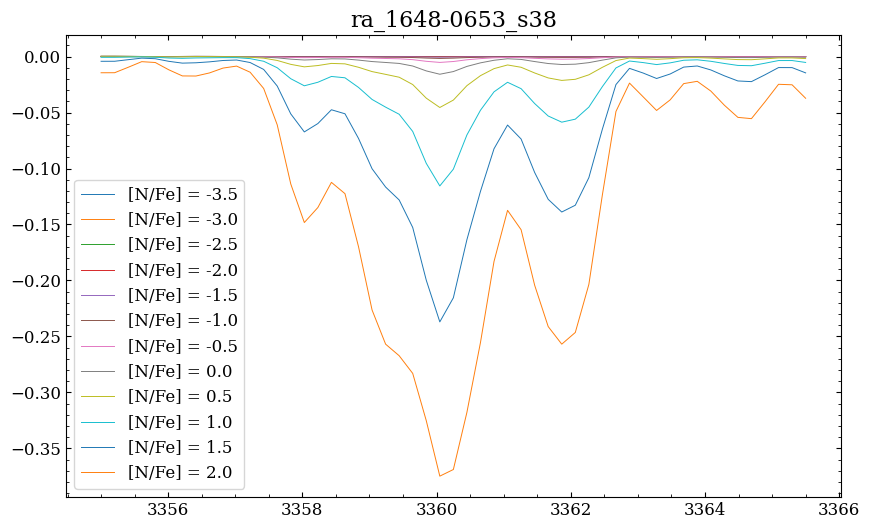

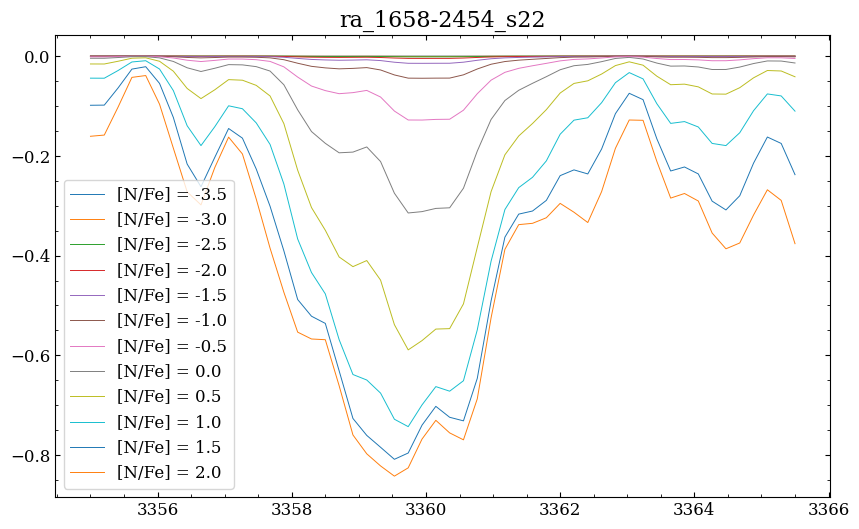

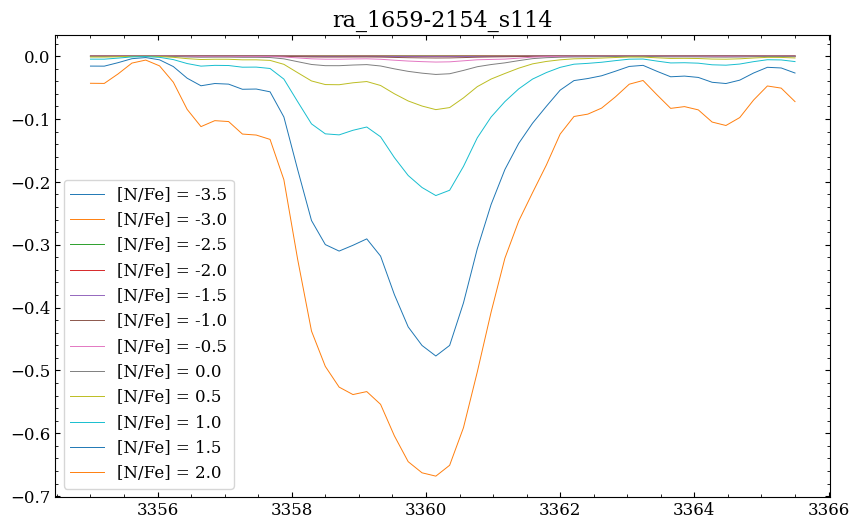

In [47]:
def get_synth2(star, el, abunds):
    
    # Getting the list of synthetic spectra
    path = f'/data/misfit/benlowe/xshooter/korg_data/upper_limits_iter/{star}/{el}/synth_specs/'
    specs = [path + f for f in os.listdir(path) if f.endswith('.csv') and not f.startswith(el)]
    specs.sort()
    # abunds = np.arange(1, -4.01, -0.01)


    # Loading in the observed spectra (all the same, so will take the first entry)
    obs_df = pd.read_csv(specs[0])
    obs_flux = obs_df['obs_flux'].to_numpy()
    obs_flux_err = obs_df['obs_flux_err'].to_numpy()
    obs_wave = obs_df['obs_wave'].to_numpy()
    

    # Loading in the empty spectra
    empty_path = f'/data/misfit/benlowe/xshooter/korg_data/upper_limits_iter/{star}/{el}/empty_specs/'
    empty_specs = [empty_path + f for f in os.listdir(empty_path) if f.endswith('.csv') and not f.startswith(el)]
    empty_df = pd.read_csv(empty_specs[0])
    empty_flux = empty_df['empty_flux']
    empty_wave = empty_df['empty_wave']


    # Loading in the synthetic spectra
    synth_all = []
    for f in specs:
        
        # Getting the synthetic specra for our desired abudnances
        try:
            synth_abund = float((f.split('/')[-1]).split('_')[0])
        except ValueError:
            continue
        if synth_abund in abunds:
            synth_df = pd.read_csv(f)
            synth_flux = synth_df['synth_flux'].to_numpy()
            synth_wave = synth_df['synth_wave'].to_numpy()
            
            synth_dict = {'abund': synth_abund, 'wave': synth_wave, 'flux': synth_flux}
            synth_all.append(synth_dict)
            
    synth_all_df = pd.DataFrame(synth_all)
    synth_all_df = synth_all_df.sort_values(by='abund')
    
    # display(synth_all_df)
    # display(synth_all_df.iloc[0])
    
    # for i in range(len(synth_all_df)-1):
    #     abund_1 = synth_all_df.iloc[i+1]['abund']
    #     flux_1 = synth_all_df.iloc[i+1]['flux']
        
    #     abund_2 = synth_all_df.iloc[i]['abund']
    #     flux_2 = synth_all_df.iloc[i]['flux']
        
    #     diff_flux = np.array(flux_1) - np.array(flux_2)
    #     mean_diff_flux = np.mean(diff_flux)
    #     print(abund_1, abund_2)
    #     print(mean_diff_flux)
    
    
    # Taking the difference between the synthetic spectra and the empty spectrum
    plt.figure(figsize=(10,6))
    for i in range(len(synth_all_df)):
        ith_flux = np.array(synth_all_df.iloc[i]['flux'])
        ith_abund = synth_all_df.iloc[i]['abund']
        
        diff_flux = ith_flux - np.array(empty_flux)
        mean_diff_flux = np.mean(diff_flux)
        
        plt.title(star)
        plt.plot(synth_all_df.iloc[i]['wave'], diff_flux, label=f"[N/Fe] = {ith_abund}", alpha=1, linewidth=0.7)
        
        print(ith_abund)
        print(mean_diff_flux)
        
    plt.legend()
    
    # synth_all_df['diff_flux'] = synth_all_df['fit_flux'].diff().fillna(0)


    # # Subtract each subequent synthetic spectrum from the previous one, then appending back into dataframe
    # synth_dff_all = []
    # for i in range(len(synth_all_df)):
    #     diff_flux = np.array(synth_all_df['flux'][i]) - np.array(synth_all_df['flux'][i+1])
    #     dif_abund = f"{synth_all_df['abund'][i]} - {synth_all_df['abund'][i+1]}"
        
    #     diff_dict = {'abund_diff': dif_abund, 'diff_flux': diff_flux}
    #     synth_dff_all.append(diff_dict)
        
    # synth_dff_df = pd.DataFrame(synth_dff_all)
    # # display(synth_dff_df.iloc[0])
        
        
    
    
    

    # # Plotting
    # plt.figure(figsize=(10,6))

    # # Plotting the observed dataset
    # plt.plot(obs_wave, obs_flux, color='black', label='Observed', linewidth=1.5)
    # plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', color='grey', alpha=0.5, markersize=2)

    # # # Plotting the empty dataset
    # # plt.plot(empty_wave, empty_flux, color='black', label='Empty', linestyle='--', linewidth=2.5)

    # # Plotting the synthetic dataset
    # # print(star)
    # for i in range(len(synth_all_df)):
    #     print(synth_all_df['abund'][i])
    #     plt.plot(synth_all_df['wave'][i], synth_all_df['flux'][i], label=f"[N/Fe] = {synth_all_df['abund'][i]}", alpha=1, linewidth=0.7)
        
    # # plt.legend(fancybox=False)
    # plt.xlabel('Wavelength (Å)')
    # plt.ylabel('Normalised Flux')
    # plt.title(f'{star}')
    # plt.xlim(3355, 3365)
    # plt.tight_layout()

    # # plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1658-2454_s22_N_synths_v2.png', dpi=300, bbox_inches='tight')
    
N_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278', 
        'ra_1633-2814_s284', 'ra_1648-0653_s38', 'ra_1658-2454_s22', 'ra_1659-2154_s114']

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.0, -0.5)]
for star in N_stars:
    get_synth2(star, "N_I", abunds)

,abund,wave,flux
5,-3.0,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8932798347373158, 0.8678260509643205, 0.865..."
4,-2.5,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8932805588818513, 0.8678270951101088, 0.865..."
3,-2.0,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8932872498692204, 0.8678347706269991, 0.865..."
2,-1.5,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8932974239296096, 0.8678532621749899, 0.865..."
1,-1.0,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8933390010948868, 0.8679132261576579, 0.865..."
0,-0.5,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8934516021693214, 0.8680780082587091, 0.865..."
6,0.0,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8937500033982444, 0.8684836422705428, 0.865..."
7,0.5,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8945121022433905, 0.8695461364649226, 0.866..."
8,1.0,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8960609262883737, 0.8718881211446761, 0.869..."
9,1.5,"[3340.0214205804373, 3340.221445818221, 3340.4...","[0.8979212980598539, 0.8756568969835569, 0.871..."


abund                                                 -3.0
wave     [3340.0214205804373, 3340.221445818221, 3340.4...
flux     [0.8932798347373158, 0.8678260509643205, 0.865...
Name: 5, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
0.0
0.5
1.0
1.5


,abund,wave,flux
5,-3.0,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7839372135719638, 0.7705580716344889, 0.796..."
4,-2.5,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7839399019564052, 0.7705609568791079, 0.796..."
3,-2.0,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7839478273325633, 0.7705697360626292, 0.796..."
2,-1.5,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.783975404939032, 0.7706007306737526, 0.7968..."
1,-1.0,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7840556762369214, 0.7706885417994834, 0.796..."
0,-0.5,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7843066597710219, 0.7709628588612291, 0.797..."
6,0.0,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7849919859043369, 0.7716919978258653, 0.797..."
7,0.5,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7867434163121809, 0.7734338315274074, 0.799..."
8,1.0,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7904311412688355, 0.7770880975422122, 0.801..."
9,1.5,"[3340.1661177408164, 3340.3660319207142, 3340....","[0.7951673397185043, 0.7815640648066376, 0.803..."


abund                                                 -3.0
wave     [3340.1661177408164, 3340.3660319207142, 3340....
flux     [0.7839372135719638, 0.7705580716344889, 0.796...
Name: 5, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
0.0
0.5
1.0
1.5


,abund,wave,flux
5,-3.0,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8714870717630129, 0.8515039249953648, 0.876..."
4,-2.5,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8714875225973048, 0.8515045414603819, 0.876..."
3,-2.0,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8714913674856081, 0.8515088492305085, 0.876..."
2,-1.5,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8715018601211482, 0.8515216434890814, 0.876..."
1,-1.0,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8715370632026342, 0.8515646407756304, 0.876..."
0,-0.5,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8716320768093007, 0.8516740747360114, 0.876..."
6,0.0,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8718920706303988, 0.8519684669388758, 0.876..."
7,0.5,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.87256479231964, 0.8527115685030594, 0.87717..."
8,1.0,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8742742816061821, 0.8546053717459124, 0.878..."
9,1.5,"[3340.1363379553786, 3340.336346119331, 3340.5...","[0.8773140334149448, 0.8579706186112949, 0.880..."


abund                                                 -3.0
wave     [3340.1363379553786, 3340.336346119331, 3340.5...
flux     [0.8714870717630129, 0.8515039249953648, 0.876...
Name: 5, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
0.0
0.5
1.0
1.5
2.0


,abund,wave,flux
5,-3.0,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8223453141052974, 0.8181808964648539, 0.849..."
4,-2.5,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8223459492395804, 0.8181816230266222, 0.849..."
3,-2.0,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8223479543974105, 0.8181839144779405, 0.849..."
2,-1.5,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8223572532191042, 0.8181940767925974, 0.849..."
1,-1.0,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8223832523021463, 0.8182223929046278, 0.849..."
0,-0.5,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8224393344865155, 0.8182795924383394, 0.849..."
6,0.0,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8226556154351582, 0.8185077027202546, 0.849..."
7,0.5,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8230411583067052, 0.8188859955596217, 0.849..."
8,1.0,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8239995311648431, 0.8198071941981988, 0.850..."
9,1.5,"[3340.2020272627565, 3340.401871825833, 3340.6...","[0.8261189671831762, 0.8217885051193837, 0.851..."


abund                                                 -3.0
wave     [3340.2020272627565, 3340.401871825833, 3340.6...
flux     [0.8223453141052974, 0.8181808964648539, 0.849...
Name: 5, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
0.0
0.5
1.0
1.5
2.0


,abund,wave,flux
6,-3.0,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7673740409331353, 0.7383744660169722, 0.745..."
5,-2.5,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7673741723533883, 0.738374642547669, 0.7456..."
4,-2.0,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7673749353151044, 0.7383755347418761, 0.745..."
3,-1.5,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.767388565070072, 0.7383890157566921, 0.7456..."
2,-1.0,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7674126131810972, 0.7384219959291867, 0.745..."
1,-0.5,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7674987144668491, 0.7385289233976587, 0.745..."
0,-0.0,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7677579422604655, 0.7388540150301253, 0.746..."
7,0.5,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7684652439425846, 0.7397276971666457, 0.746..."
8,1.0,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7702179973525936, 0.7419252111784908, 0.748..."
9,1.5,"[3340.0669828713812, 3340.266855229881, 3340.4...","[0.7734940629175012, 0.7464013804898421, 0.751..."


abund                                                 -3.0
wave     [3340.0669828713812, 3340.266855229881, 3340.4...
flux     [0.7673740409331353, 0.7383744660169722, 0.745...
Name: 6, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
-0.0
0.5
1.0
1.5
2.0


,abund,wave,flux
6,-3.0,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8149277734977215, 0.7888827155540677, 0.786..."
5,-2.5,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8149285195247591, 0.7888834872771974, 0.786..."
4,-2.0,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8149359865726988, 0.7888909705397463, 0.786..."
3,-1.5,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8149488128956404, 0.7889087769544709, 0.786..."
2,-1.0,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8149978008431485, 0.7889678098171872, 0.786..."
1,-0.5,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.815137903339518, 0.7891363071359274, 0.7864..."
0,-0.0,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8155986249414058, 0.7898243092303098, 0.787..."
7,0.5,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8165716187289349, 0.7910016481597989, 0.788..."
8,1.0,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8186707095402281, 0.7937605727673083, 0.790..."
9,1.5,"[3340.017890515186, 3340.2179035633026, 3340.4...","[0.8214928047125988, 0.7983250813935401, 0.794..."


abund                                                 -3.0
wave     [3340.017890515186, 3340.2179035633026, 3340.4...
flux     [0.8149277734977215, 0.7888827155540677, 0.786...
Name: 6, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
-0.0
0.5
1.0
1.5
2.0


,abund,wave,flux
5,-3.0,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7818253866248088, 0.7399098477814625, 0.761..."
4,-2.5,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7818658557947833, 0.7399532648718362, 0.761..."
3,-2.0,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7820039842658968, 0.7401012561599074, 0.761..."
2,-1.5,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7824180269070184, 0.7405205584622118, 0.761..."
1,-1.0,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7836061422728755, 0.7417428218440172, 0.762..."
0,-0.5,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.786471344294544, 0.7447402274237662, 0.7642..."
6,0.0,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7903133463580805, 0.748893459687828, 0.7655..."
7,0.5,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7916203019800834, 0.7513192810729111, 0.759..."
8,1.0,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7886313966254027, 0.7488232394082148, 0.744..."
9,1.5,"[3340.1193925918046, 3340.319363818086, 3340.5...","[0.7844053393578331, 0.7424625216916, 0.727156..."


abund                                                 -3.0
wave     [3340.1193925918046, 3340.319363818086, 3340.5...
flux     [0.7818253866248088, 0.7399098477814625, 0.761...
Name: 5, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
0.0
0.5
1.0
1.5
2.0


,abund,wave,flux
5,-3.0,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7925506645091073, 0.7623347557014674, 0.788..."
4,-2.5,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7925507723762548, 0.7623348327969734, 0.788..."
3,-2.0,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7925581518791137, 0.7623418392656954, 0.788..."
2,-1.5,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7925862100190995, 0.7623685544906678, 0.788..."
1,-1.0,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7926623362253227, 0.7624531115915121, 0.788..."
0,-0.5,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7927858971544849, 0.7624943810152863, 0.788..."
6,0.0,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.793399183332314, 0.763121169507751, 0.78897..."
7,0.5,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.79506787227174, 0.7648727906936148, 0.79025..."
8,1.0,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.7983183675246991, 0.7684581331484545, 0.792..."
9,1.5,"[3340.120784256558, 3340.320863373864, 3340.52...","[0.8008061773420221, 0.7718657042640411, 0.790..."


abund                                                 -3.0
wave     [3340.120784256558, 3340.320863373864, 3340.52...
flux     [0.7925506645091073, 0.7623347557014674, 0.788...
Name: 5, dtype: object

-3.0
-2.5
-2.0
-1.5
-1.0
-0.5
0.0
0.5
1.0
1.5
2.0


### Plotting Li for star ra_1633-2814_s130

In [3]:
li_df = pd.read_csv('/data/misfit/benlowe/xshooter/korg_data/abunds/final_iter/ra_1633-2814_s130/Li_I/iter_1/Li_results.csv')

obs_wave = li_df['obs_wave'].to_numpy()
obs_flux = li_df['obs_flux'].to_numpy()
fit_wave = li_df['fit_wave'].to_numpy()
fit_flux = li_df['fit_flux'].to_numpy()
li_df

,fit_wave,line,abund_xfe,err,chisqr,weight,fit_flux,obs_flux,obs_wave,abund_xh
0,"[[6700.098520916285, 6700.298392598197, 6700.4...",Li_6707.813,4.364162,0.020321,54.276622,2421.660538,"[[0.9840029100457197, 0.9840231821476424, 0.98...","[[0.972075557950521, 0.9688362470442071, 0.971...","[[6695.101728868589, 6695.301600550499, 6695.5...",0.993131


In [4]:
obs_wave

array(['[[6695.101728868589, 6695.301600550499, 6695.50147223241, 6695.701343914311, 6695.901215596226, 6696.101087278131, 6696.300958960041, 6696.500830641952, 6696.7007023238575, 6696.900574005769, 6697.100445687673, 6697.300317369583, 6697.50018905149, 6697.700060733395, 6697.89993241531, 6698.099804097209, 6698.299675779123, 6698.499547461024, 6698.6994191429385, 6698.899290824846, 6699.099162506756, 6699.299034188658, 6699.498905870568, 6699.698777552471, 6699.898649234386, 6700.098520916285, 6700.298392598197, 6700.49826428011, 6700.698135962012, 6700.898007643928, 6701.097879325828, 6701.297751007744, 6701.497622689645, 6701.697494371556, 6701.897366053467, 6702.0972377353655, 6702.297109417278, 6702.496981099183, 6702.696852781094, 6702.896724463001, 6703.0965961449165, 6703.29646782682, 6703.4963395087225, 6703.696211190641, 6703.896082872539, 6704.0959545544565, 6704.295826236358, 6704.495697918272, 6704.695569600173, 6704.895441282087, 6705.095312963996, 6705.295184645898, 6

### Plotting Na I for star ra_1633-2814_s130

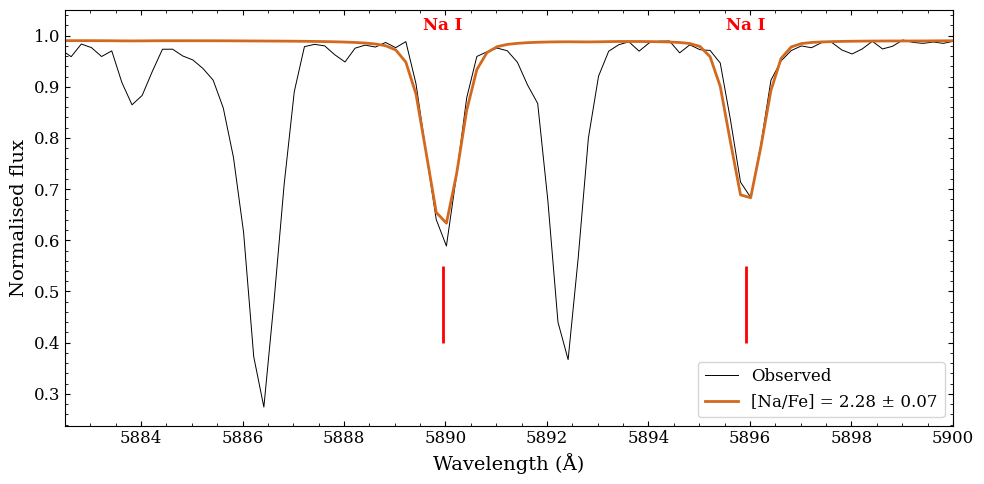

In [36]:
# Loading in the synthetic and observed datasets
data_df = pd.read_csv("/data/misfit/benlowe/xshooter/korg_data/tests/ra_1633-2814_s130_Na/ra_1633-2814_s130/Na_I/iter_1/Na_results.csv")

obs_wave = ast.literal_eval(data_df['obs_wave'].to_numpy()[0])[0]
obs_flux = ast.literal_eval(data_df['obs_flux'].to_numpy()[0])[0]
bestfit_wave = ast.literal_eval(data_df['fit_wave'].to_numpy()[0])[0]
bestfit_flux = ast.literal_eval(data_df['fit_flux'].to_numpy()[0])[0]
# obs_flux = data_df['flux']
# fit_flux = data_df['best_fit']


plt.figure(figsize=[10,5])
plt.plot(obs_wave, obs_flux, color='black', linewidth=0.7, label='Observed')
plt.plot(bestfit_wave, bestfit_flux, color='chocolate', label='[Na/Fe] = 2.28 ± 0.07', linewidth=2)
plt.vlines(x=5889.951, ymin=0.4, ymax=0.55, color='red', linewidth=2)
plt.vlines(x=5895.924, ymin=0.4, ymax=0.55, color='red', linewidth=2)
plt.text(5889.951, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')
plt.text(5895.924, 1.01, 'Na I', color='red', fontsize=12, ha='center', fontweight='bold')

plt.xlabel('Wavelength (Å)')
plt.ylabel('Normalised flux')
plt.ylim(top=1.05)
plt.xlim(left=5882.5, right=5900)
plt.legend(fancybox=True)
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_fit.png', dpi=300, bbox_inches='tight')
plt.savefig('/data/misfit/benlowe/xshooter/results/star_abunds/ra_1633-2814_s130_Na_fit.pdf', dpi=300, bbox_inches='tight')

In [8]:
print(obs_flux)

[0.9783819930403023, 0.9888607312249689, 0.9667143857151616, 0.9729042063386983, 0.9816321479629475, 0.9903809065843822, 0.986760093990184, 0.974238012908352, 0.9873087915022086, 0.9926466542767799, 0.9831030846298567, 0.9762267765252253, 0.9938057938871148, 0.9995728395895243, 0.9724323873073603, 0.9717015831323867, 0.9847056081531417, 0.9888411651011041, 0.9759949739144799, 0.9892206419972647, 0.9873401320578965, 0.9782670880191372, 0.980666135249174, 0.9910571383950106, 0.9878448581758529, 0.9793839809425546, 0.983460198377111, 0.9723194085958261, 0.9588076975977822, 0.9834893039171229, 0.9764743592749848, 0.9590804966070912, 0.9701207819113461, 0.9083430574117854, 0.8647189856473704, 0.8830424142031535, 0.9299226134733927, 0.9733215671702634, 0.9734053028232327, 0.960203288988798, 0.9523882480730624, 0.9356286087280423, 0.9128997504967743, 0.8584140275184695, 0.7622170798144806, 0.6155571687708883, 0.3725518919440852, 0.2740948131285208, 0.4807041703418946, 0.7091873470100647, 0.89

### Seeing if Li 6707 is visible in any of our stars

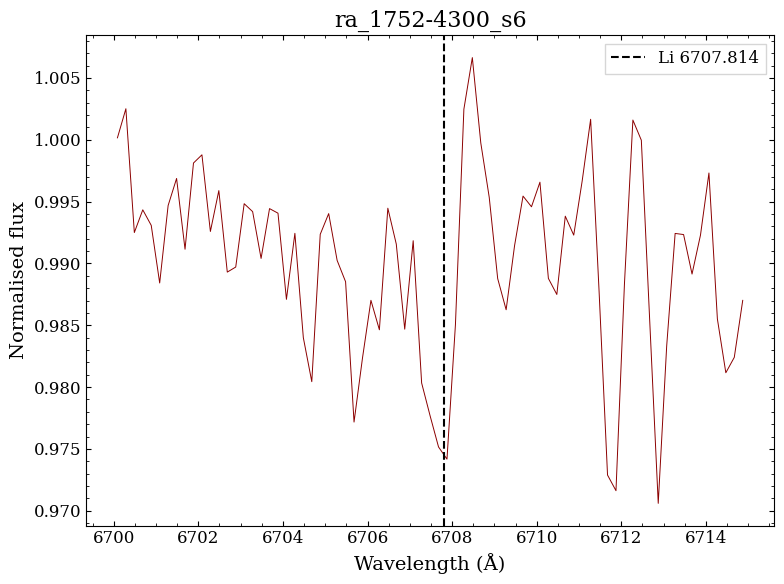

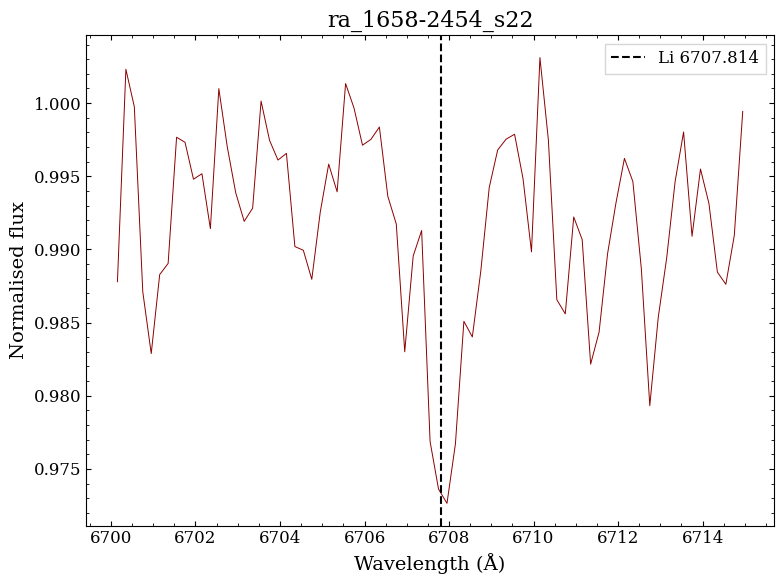

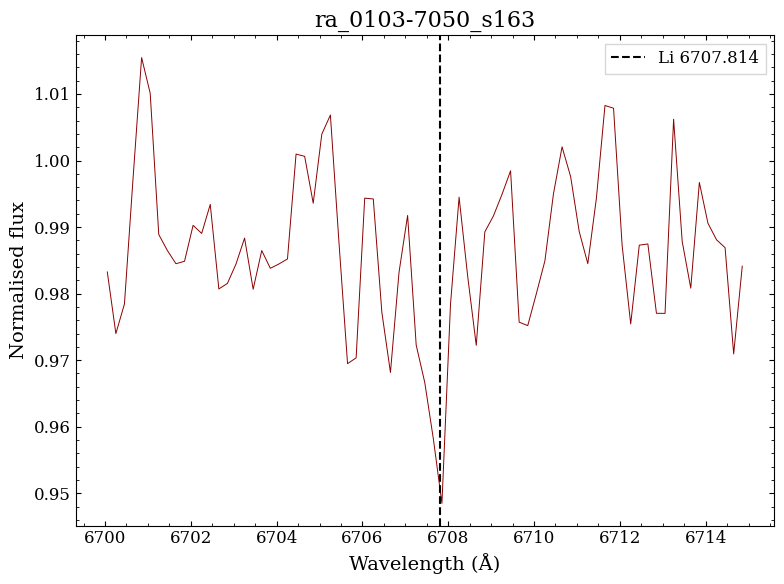

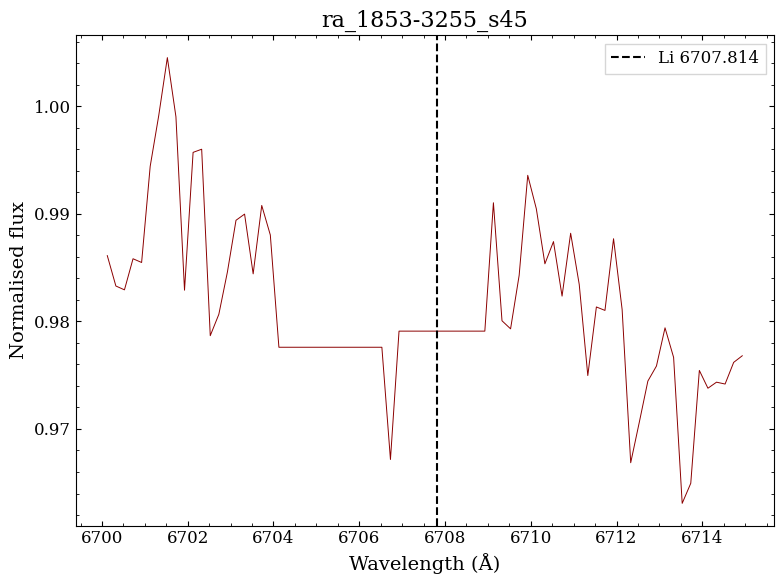

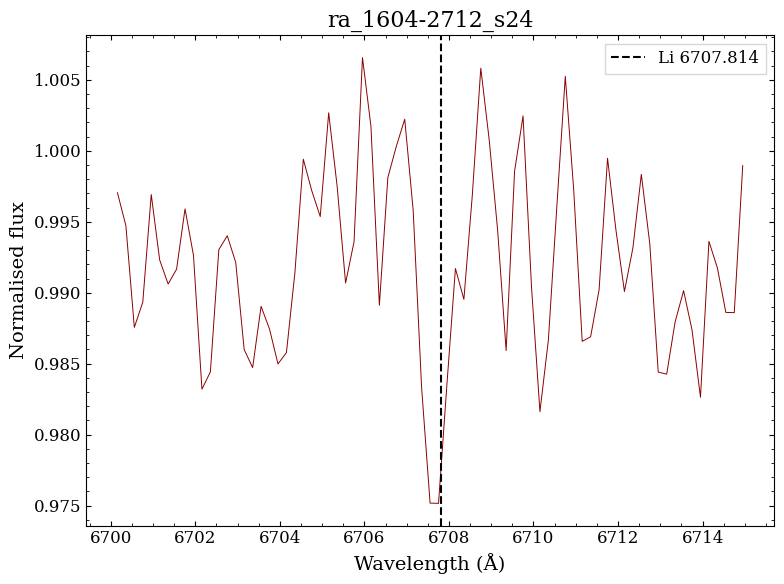

...

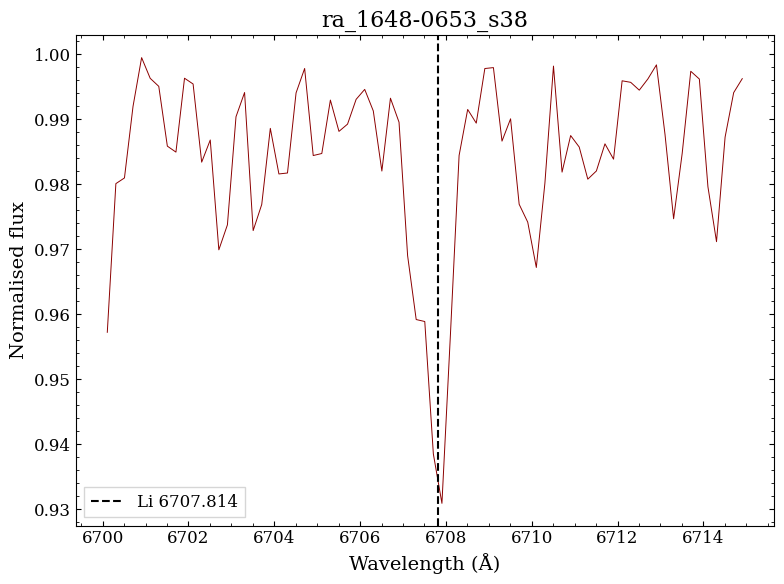

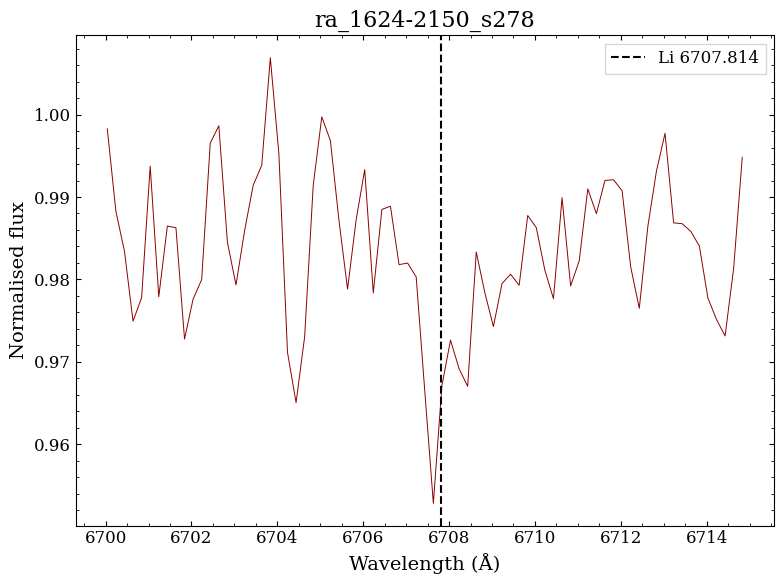

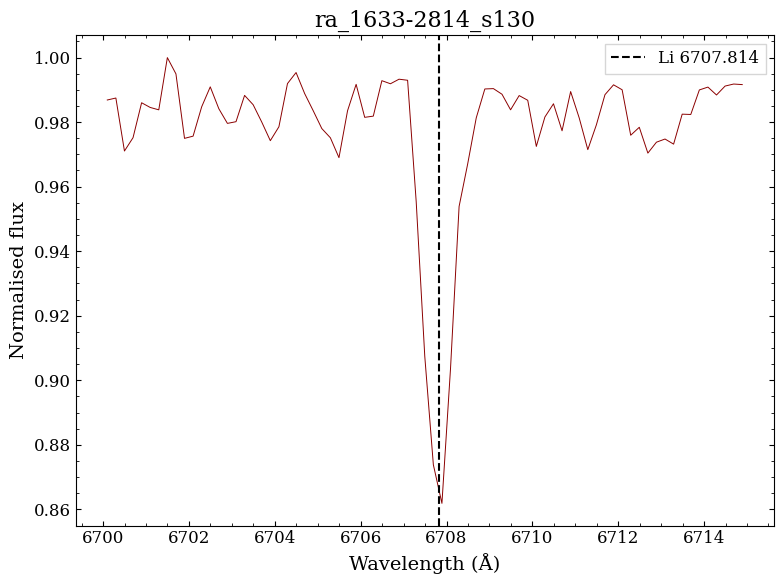

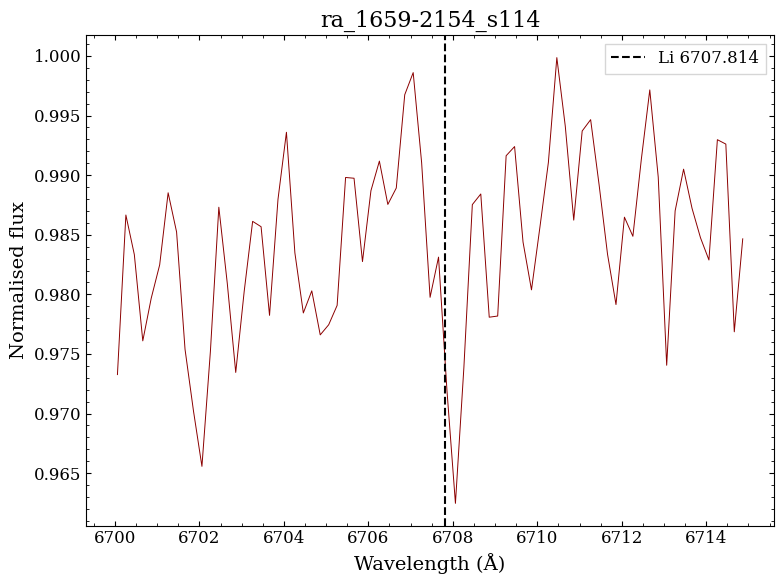

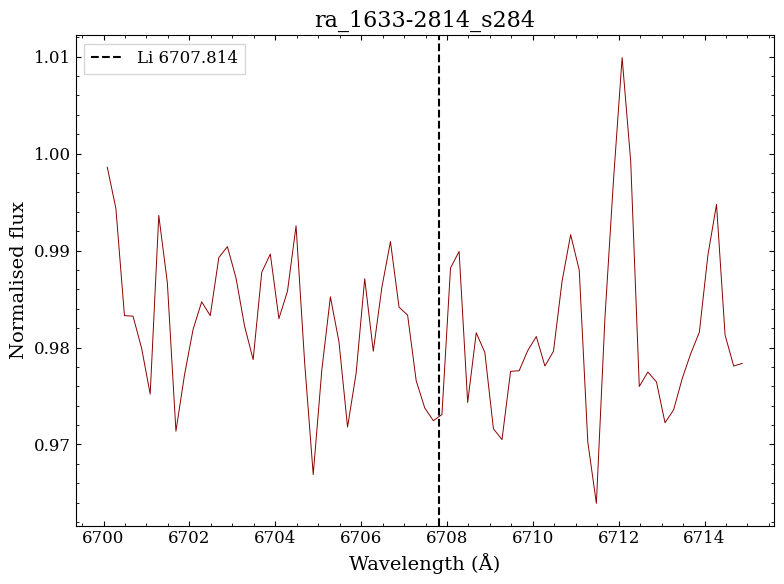

In [9]:
# Loading in the directories to the spectral data
path= '/data/misfit/benlowe/xshooter/reduced_data/comb_spec_2/'
stars = [f for f in os.listdir(path) if f[-4:] != '.csv']

# Looping through the stars
for star in stars:
    
    # Extracting the spectral data for the star
    fits_data = fits.open(f'{path + star}/{star}_data.fits')
    vis_wave = fits_data[2].data['wave']
    vis_flux = fits_data[2].data['flux']
    
    # Slicing to only include the Li 6707 region
    li_reg = np.where((vis_wave > 6700) & (vis_wave < 6715))
    
    # Rest wavelenghts of other lines in the area
    fe_wavelengths = [
    6703.56554, 6705.10050, 6708.28192, 6710.31761, 6711.81916,
    6712.50507, 6712.67363, 6713.04550, 6713.74203, 6715.38134]
    
    ni_wavelengths = [
        6711.51790, 6711.53979, 6711.55151, 6711.56363, 6711.58864]
    
    plt.figure(figsize=[8,6])
    plt.plot(vis_wave[li_reg], vis_flux[li_reg], color='darkred', linewidth=0.7)
    
    # for i, fe in enumerate(fe_wavelengths):
    #     plt.axvline(fe, color='black', linestyle='-.', linewidth=0.5, label='Fe I' if i == 0 else None)
    # for j, ni in enumerate(ni_wavelengths):
    #     plt.axvline(ni, color='black', linestyle=':', linewidth=0.5, label='Ni I' if j == 0 else None)
    
    
    plt.axvline(6707.814, color='black', linestyle='--', label='Li 6707.814')
    plt.xlabel('Wavelength (Å)')
    plt.ylabel('Normalised flux')
    plt.title(star)
    plt.legend(fancybox=False)
    plt.tight_layout()
    
    # plt.savefig(f"/data/misfit/benlowe/xshooter/results/li_lines/{star}_li.pdf", dpi=300, transparent=False, facecolor="white")
    # plt.savefig(f"/data/misfit/benlowe/xshooter/results/li_lines/{star}_li.png", dpi=300, transparent=False, facecolor="white")


### Plotting the Sc 4246.82 line for star ra_1752-4300_s214

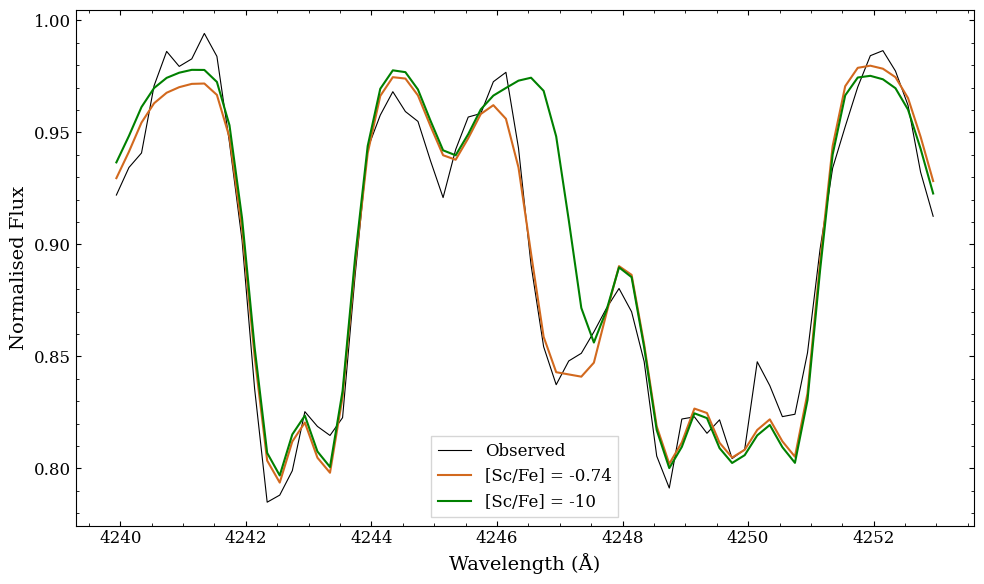

In [6]:
# Loading in the best fit and the observed spectra
bestfit_df = pd.read_csv("/data/misfit/benlowe/xshooter/korg_data/abunds/final/ra_1752-4300_s214/Sc_II/iter_2/fits_data/Sc_4246.822_fit.csv")
bestfit_flux = bestfit_df["best_fit"].values
bestfit_wave = bestfit_df["wave"].values
obs_flux = bestfit_df["flux"].values
obs_wave = bestfit_df["wave"].values

# Loading in the [Sc/Fe] = -10 fit
scm10_df = pd.read_csv("/data/misfit/benlowe/xshooter/korg_data/synths/ra_1752-4300_s214/Sc_II/obs/line_4246.822/spectra/-10.0_spec.csv")
scm10_flux = np.array(ast.literal_eval(scm10_df["fit_flux"].values[0]))
scm10_wave = np.array(ast.literal_eval(scm10_df["fit_wave"].values[0]))

# Plotting the spectra
wave_index = np.where((scm10_wave >= obs_wave[0]) & (scm10_wave <= obs_wave[-1]))[0]

plt.figure(figsize=(10, 6))
plt.plot(obs_wave, obs_flux, label="Observed", color='black', linewidth=0.8)
plt.plot(bestfit_wave, bestfit_flux, label="[Sc/Fe] = -0.74", color='chocolate')
plt.plot(scm10_wave[wave_index], scm10_flux[wave_index], label="[Sc/Fe] = -10", color='green')
plt.xlabel("Wavelength (Å)")
plt.ylabel("Normalised Flux")
plt.legend(fancybox=False)
plt.tight_layout()

plt.savefig('/data/misfit/benlowe/xshooter/results/tests/sc/ra_1752-4300_s214_ScFits.png', dpi=300, transparent=False, facecolor="white")


/tmp/ipykernel_2062794/4013475799.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 6))


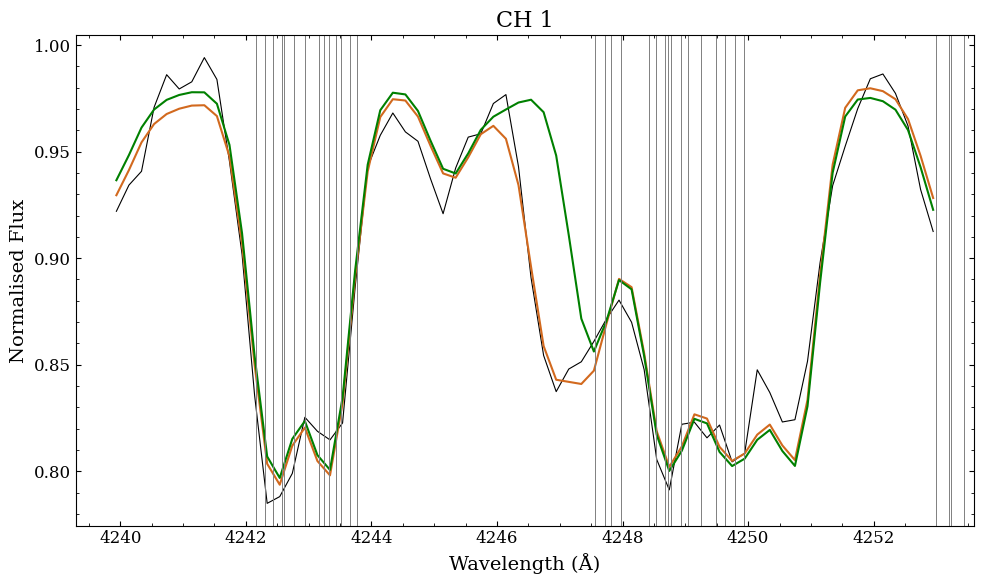

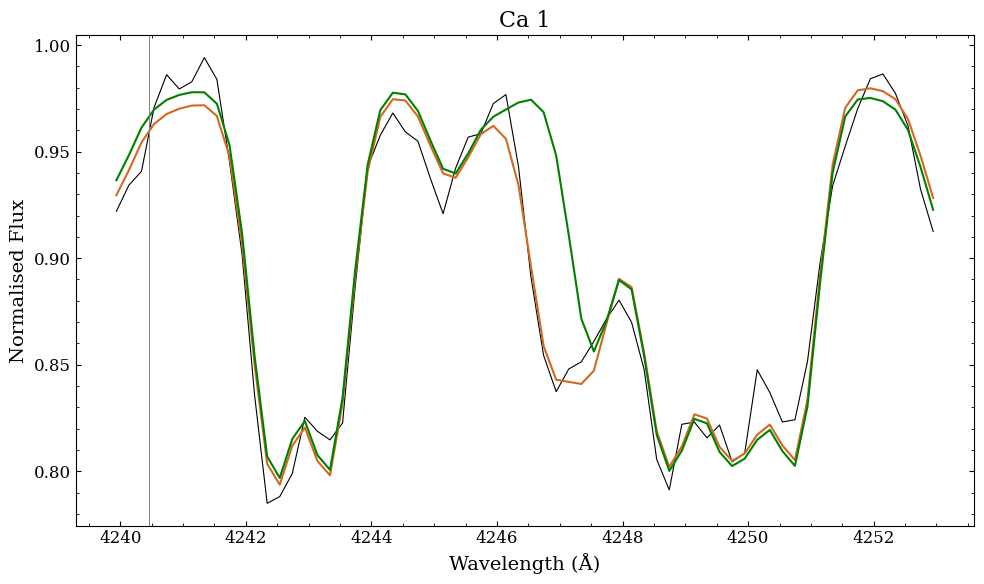

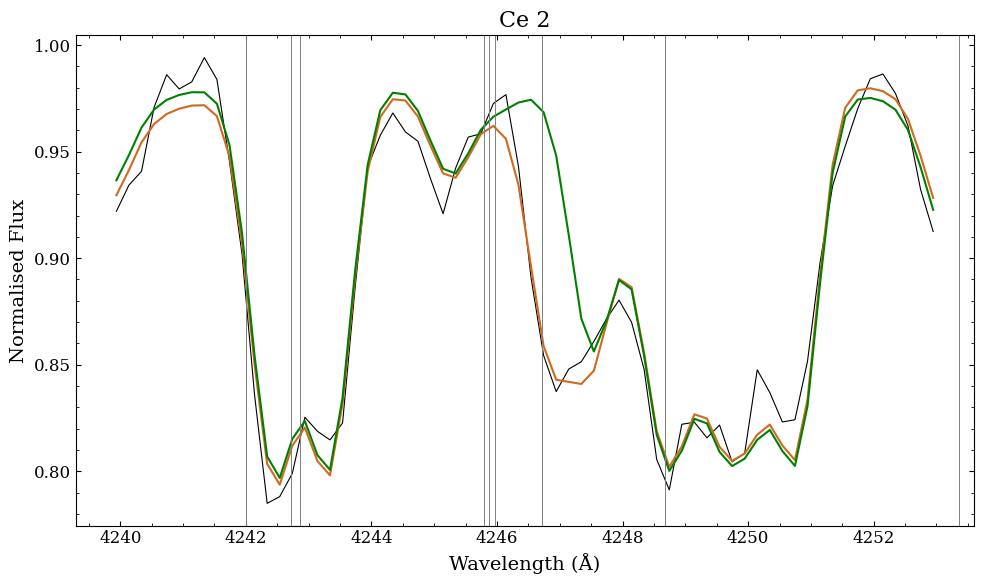

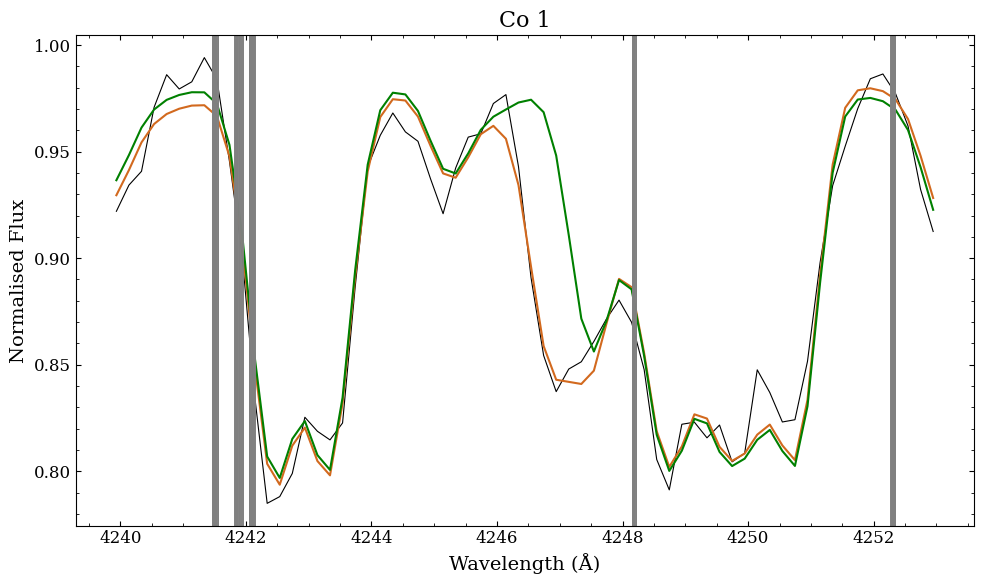

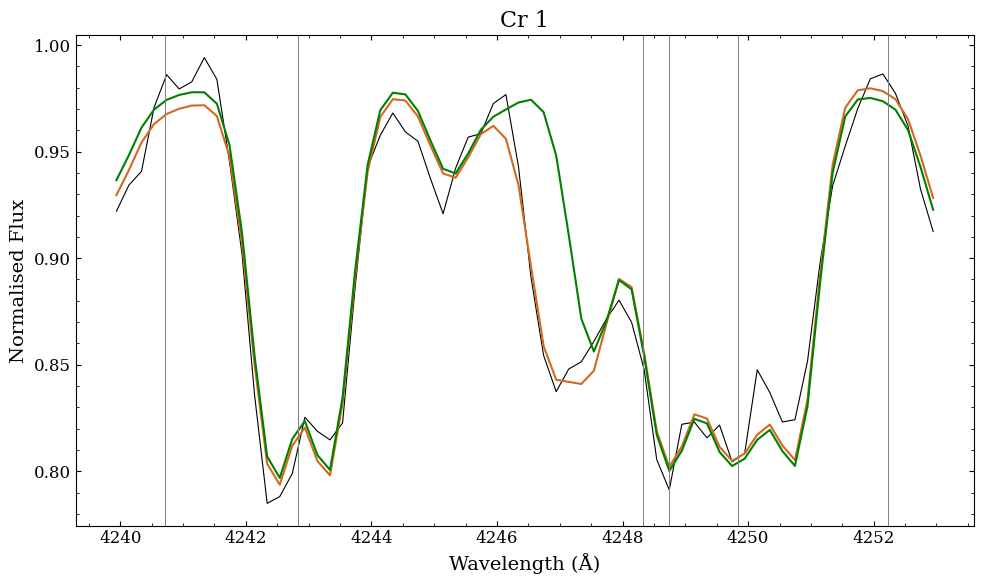

...

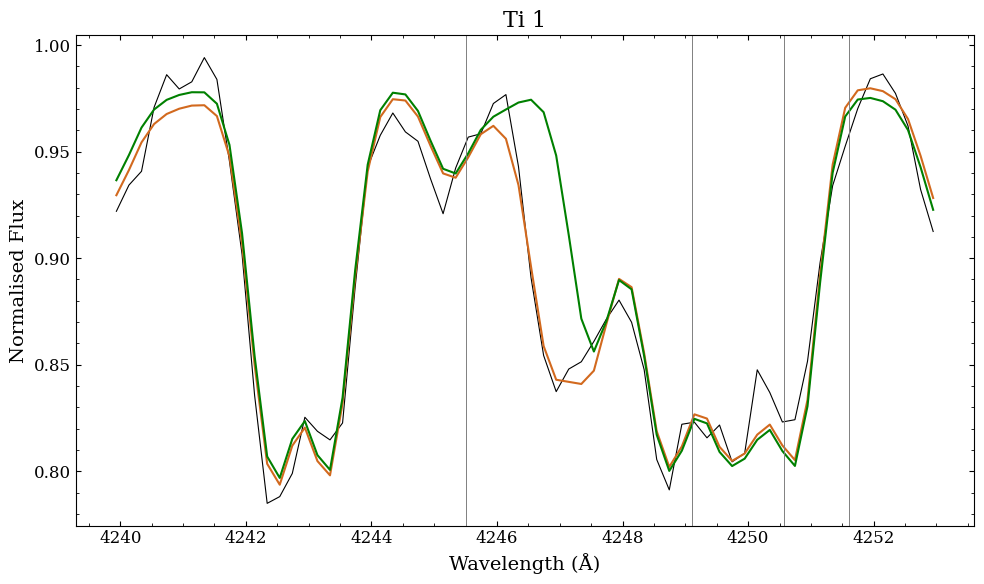

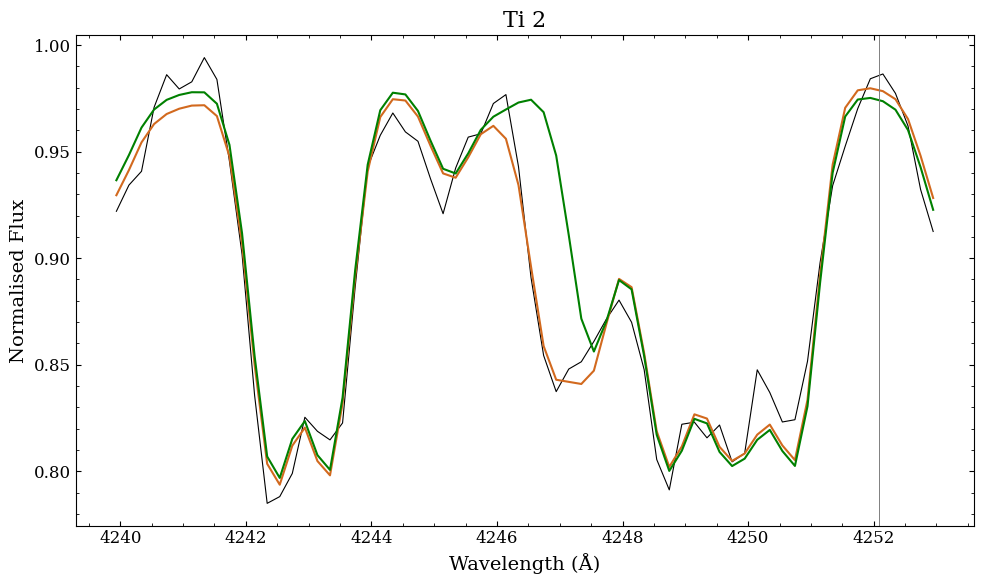

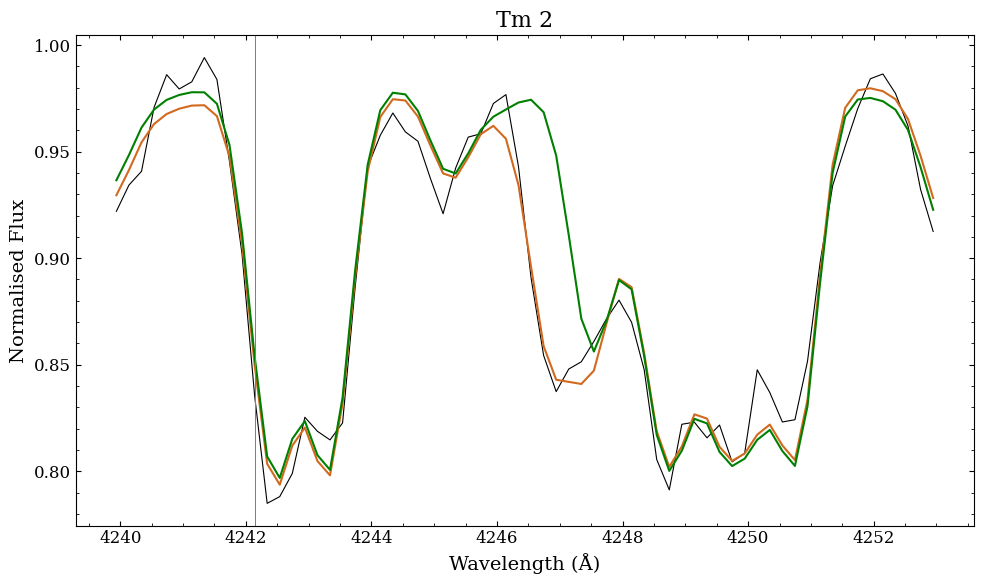

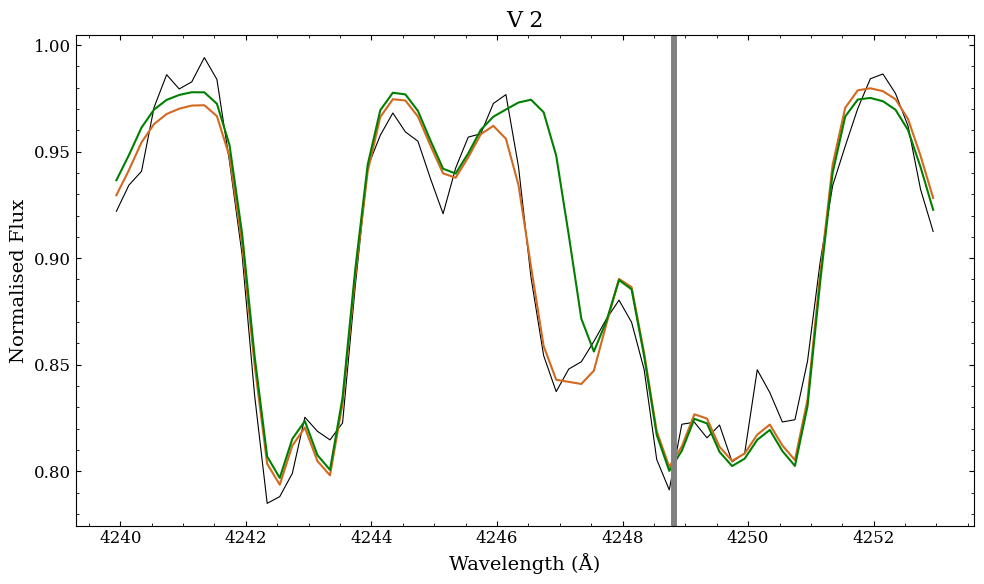

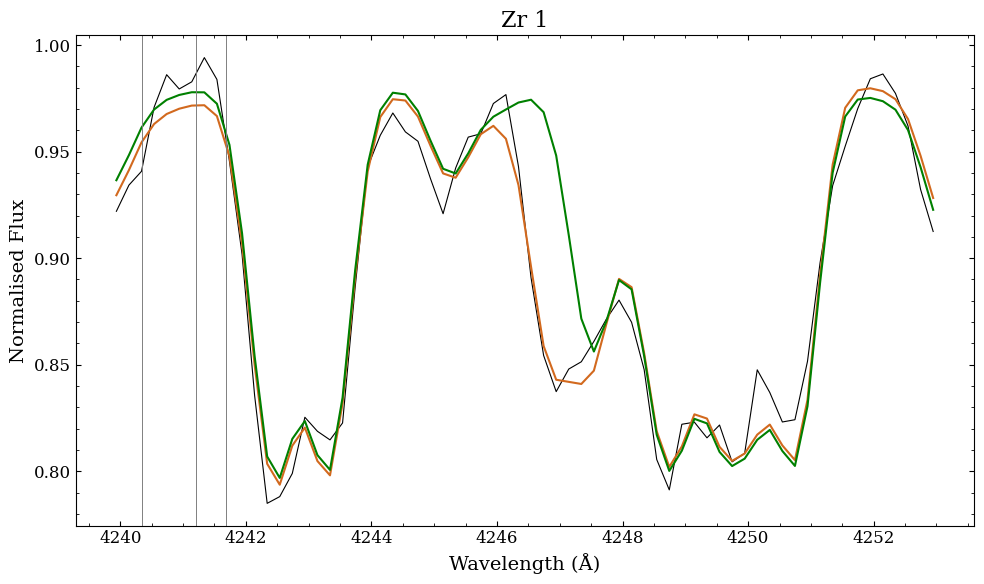

In [5]:
# Loading in the linelist for the region
lines_df = pd.read_csv('/home/benlowe/xshooter_proj/spectra/vald_4240-4530.csv')

# Separate the elemenets and wavelengths
dfs_by_element = {element: group for element, group in lines_df.groupby('element')}

els_df_list =[]
for el in list(dfs_by_element.keys()):
    el_df = dfs_by_element[el]
    els_df_list.append(el_df)
    
    
# # Plotting the lines

for el_df in els_df_list:
    plt.figure(figsize=(10, 6))
    plt.plot(obs_wave, obs_flux, label="Observed", color='black', linewidth=0.8)
    plt.plot(bestfit_wave, bestfit_flux, label="[Sc/Fe] = -0.74", color='chocolate')
    plt.plot(scm10_wave[wave_index], scm10_flux[wave_index], label="[Sc/Fe] = -10", color='green')
    
    el_wave = el_df['wavelength'].values
    el_name = el_df['element'].values[0]
    
    plt.axvline(el_wave[0], label=el_name, color='grey', linewidth=0.7)
    for wave in el_wave[1:]:
        plt.axvline(wave, color='grey', linewidth=0.7)
    
    
    plt.title(el_name)
    plt.xlabel("Wavelength (Å)")
    plt.ylabel("Normalised Flux")
    plt.tight_layout()
    
    plt.savefig(f'/data/misfit/benlowe/xshooter/results/tests/sc/ra_1752-4300_s214_ScFits_{el_name}.png', dpi=300, transparent=False, facecolor="white")

In [33]:
from juliacall import Main as jl
jl.seval("using Korg")
Korg = jl.Korg

vald_linelist = Korg.read_linelist("/data/misfit/benlowe/xshooter/linelist/vald_3300-9000_linelist_metal-poor.lin", format="vald", isotopic_abundances=Korg.isotopic_abundances)


In [48]:
import re

with open("/data/misfit/benlowe/xshooter/linelist/test.txt", encoding="utf-8") as inp, open("vald_4240-4530.csv", "w", encoding="utf-8") as out:
    out.write("element,wavelength\n")
    for line in inp:
        m = re.match(r"' *([A-Za-z0-9\+\-\(\) ]+)', *([0-9]+\.[0-9]+)", line)
        if m:
            element, wavelength = m.group(1).strip(), m.group(2)
            out.write(f"{element},{wavelength}\n")

### Looking at the Sc 4320.732 line to see if its any good

[4318.14483337 4318.34485861 4318.54488385 4318.74490908 4318.94493432
 4319.14495956 4319.3449848  4319.54501004 4319.74503527 4319.94506051
 4320.14508575 4320.34511099 4320.54513622 4320.74516146 4320.9451867
 4321.14521194 4321.34523718 4321.54526241 4321.74528765 4321.94531289]
[4318.04147441 4318.24131897 4318.44116353 4318.64100809 4318.84085266
 4319.04069722 4319.24054178 4319.44038635 4319.64023091 4319.84007547
 4320.03992004 4320.2397646  4320.43960916 4320.63945373 4320.83929829
 4321.03914285 4321.23898741 4321.43883198 4321.63867654 4321.8385211 ]
[4318.12299791 4318.3230036  4318.5230093  4318.723015   4318.92302069
 4319.12302639 4319.32303209 4319.52303779 4319.72304348 4319.92304918
 4320.12305488 4320.32306057 4320.52306627 4320.72307197 4320.92307766
 4321.12308336 4321.32308906 4321.52309476 4321.72310045 4321.92310615]
[4318.08169582 4318.28170887 4318.48172192 4318.68173496 4318.88174801
 4319.08176106 4319.28177411 4319.48178716 4319.6818002  4319.88181325
 432

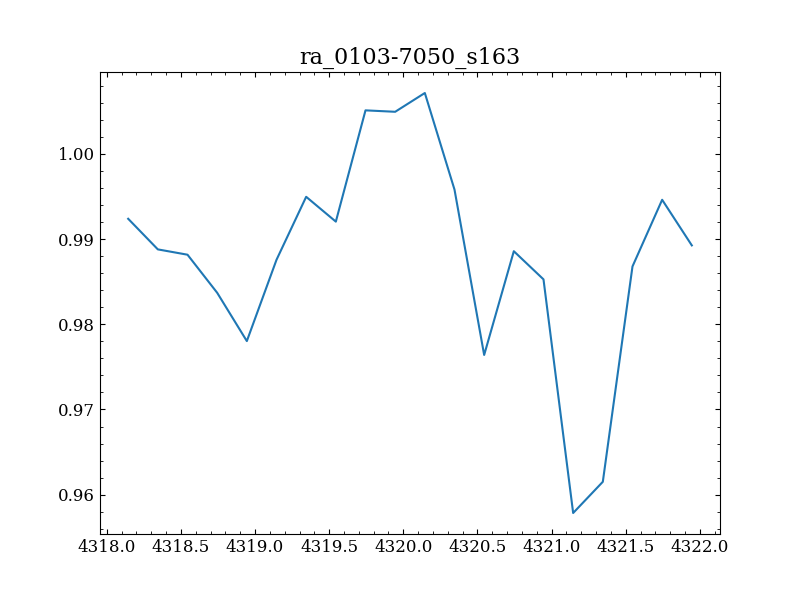

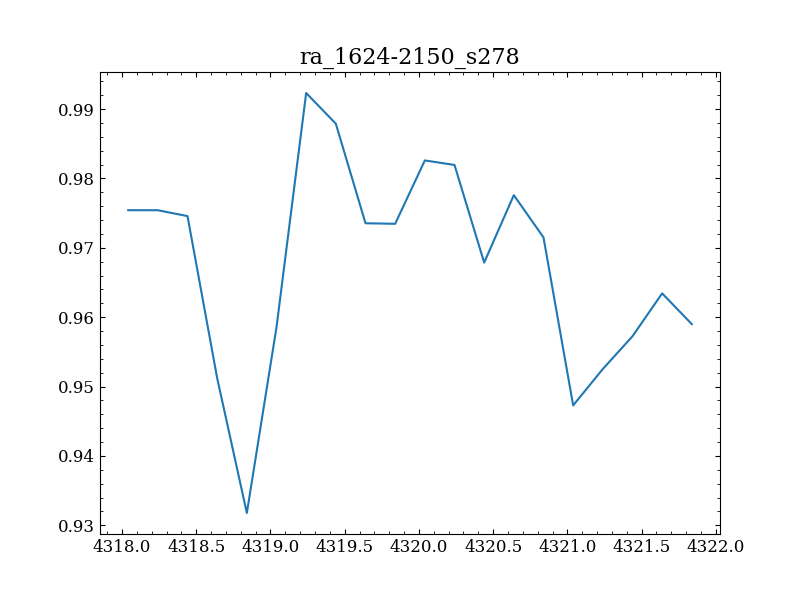

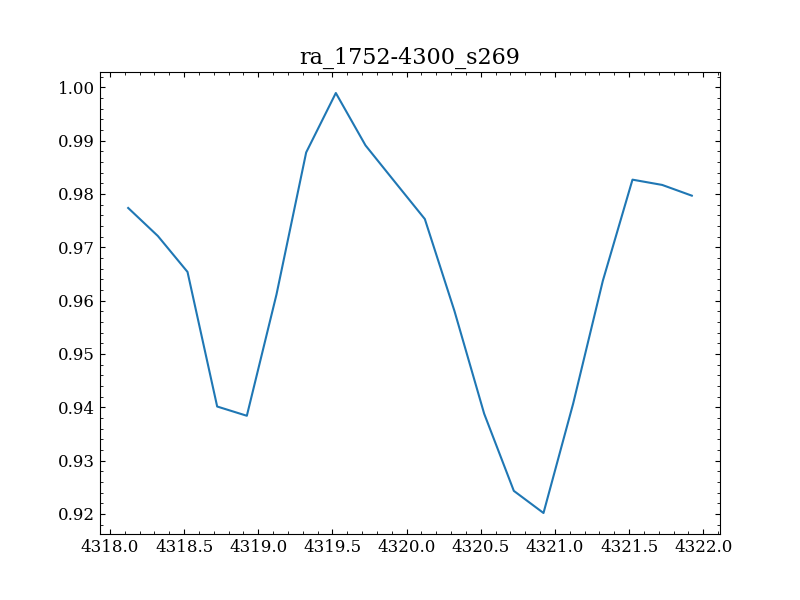

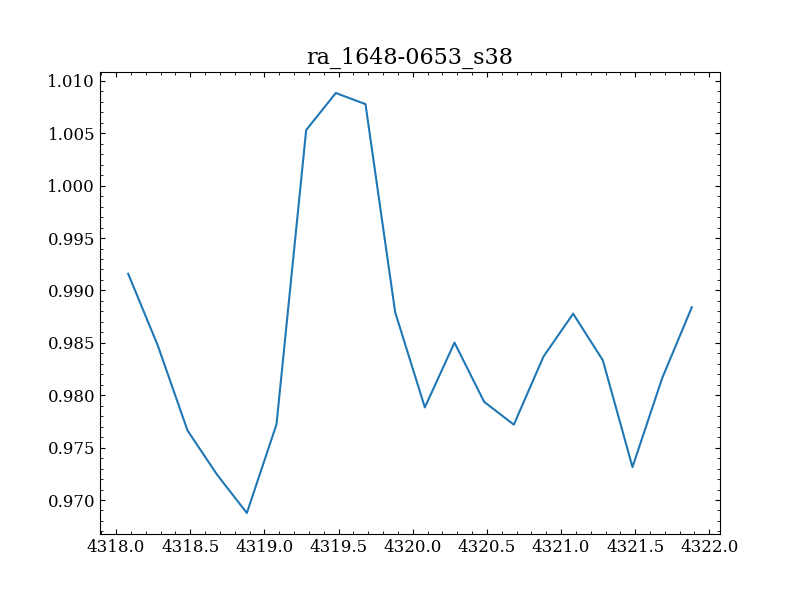

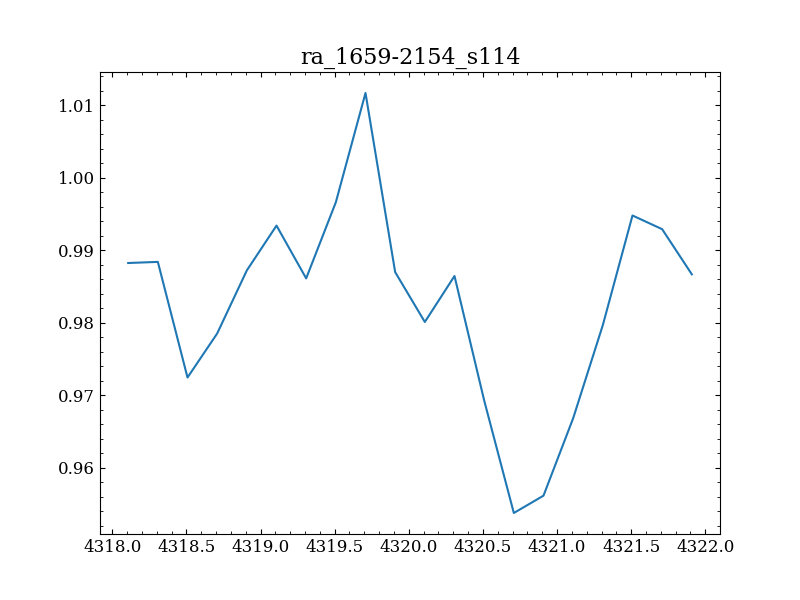

...

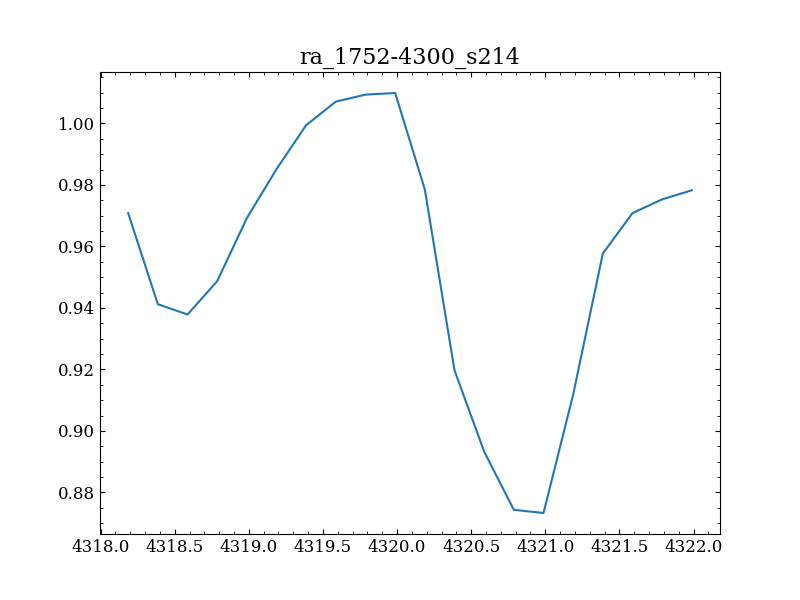

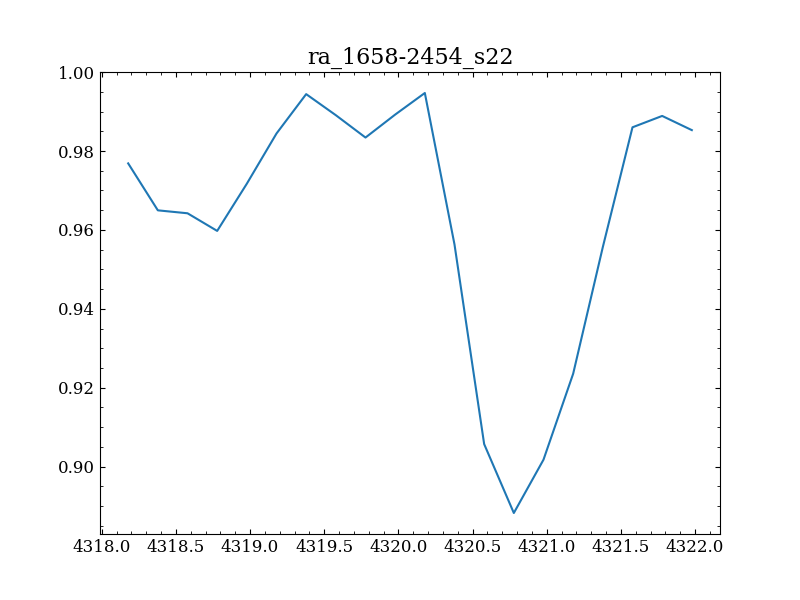

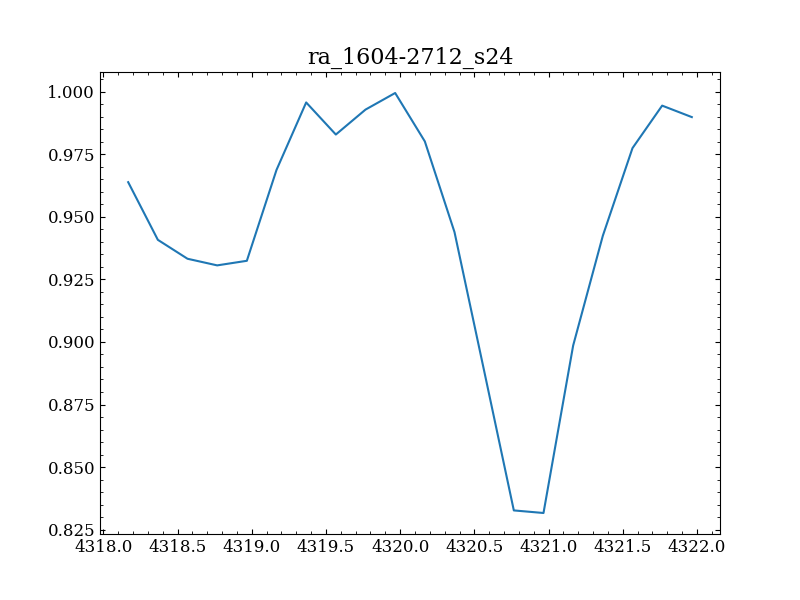

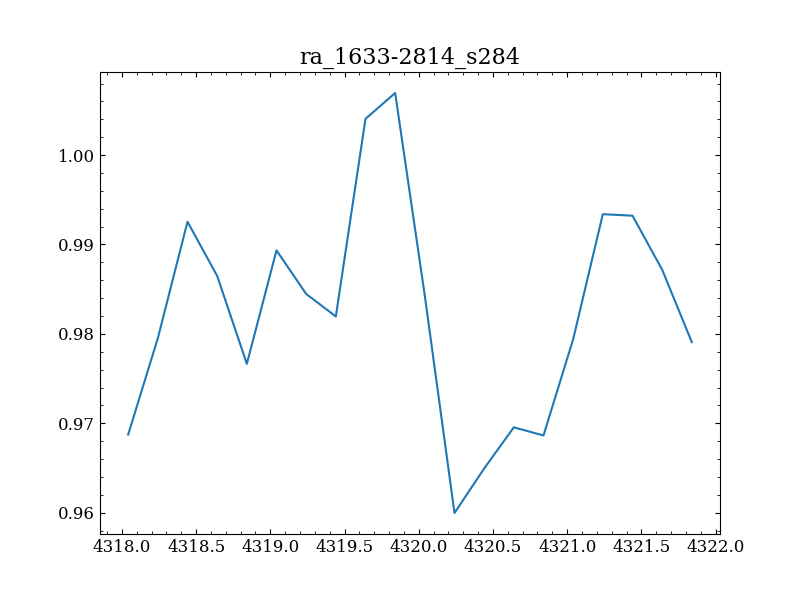

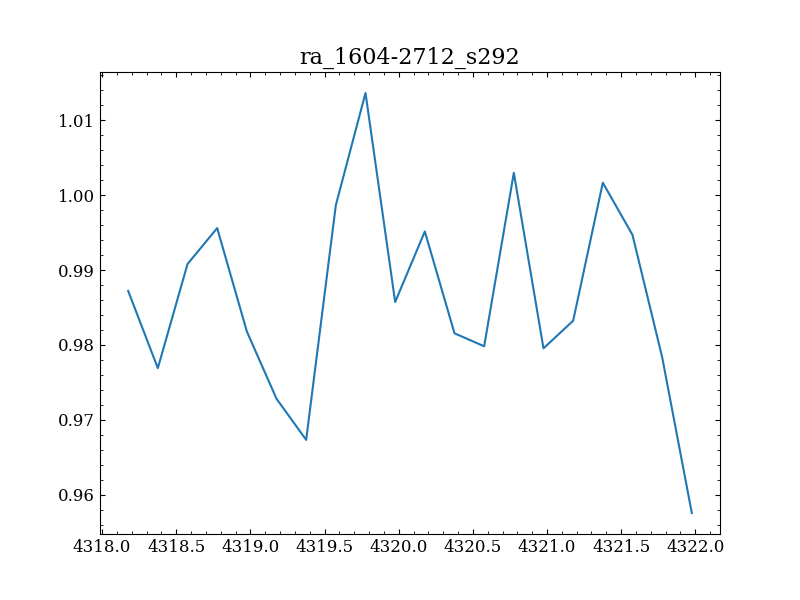

In [10]:
dir_path = "/data/misfit/benlowe/xshooter/reduced_data/comb_spec/"
star_paths = [os.path.join(dir_path, star) for star in os.listdir(dir_path) if os.path.isdir(os.path.join(dir_path, star))]

for path in star_paths:
    fits_file = fits.open(os.path.join(path, f"{path.split('/')[-1]}_data.fits"))
    
    # Loading in the UVB data
    uvb_data = fits_file[1].data
    uvb_wave = uvb_data["wave"] 
    uvb_flux = uvb_data["flux"]
    uvb_flux_err = uvb_data["flux_err"]
    

    # Plotting across the region
    wavemin = 4318
    wavemax = 4322
    uvb_mask = (uvb_wave > wavemin) & (uvb_wave < wavemax)
    uvb_wave_masked = uvb_wave[uvb_mask]
    uvb_flux_masked = uvb_flux[uvb_mask]
    uvb_flux_err_masked = uvb_flux_err[uvb_mask]
        
    plt.figure(figsize=(8, 6))
    plt.title(path.split('/')[-1])
    plt.plot(uvb_wave_masked, uvb_flux_masked)


In [10]:
aat_df = pd.read_csv('/data/misfit/benlowe/xshooter/stellar_params/aat_params_FINAL.csv')
emp_stars = [star for star in os.listdir('/data/misfit/benlowe/xshooter/reduced_data/comb_spec') if star[-3:] != 'csv']

emp_df = aat_df[aat_df['star_id'].isin(emp_stars)]
emp_df.sort_values('star_id')
emp_df = emp_df.drop_duplicates(subset=['star_id'])

emp_df.to_csv('/data/misfit/benlowe/xshooter/stellar_params/emp_params_FINAL.csv')



### Stacking spectra

First getting all the .fits data

In [6]:
def grab_fits(star_path):
    """
    Grabs the UVB, VIS and NIR fits files for a given star.
    
    Parameters
    ----------
    star_path : str
        Path to the directory containing the UVB, VIS and NIR data.
    
    Returns
    -------
    uvb_fits : list
        List of UVB fits files.
    vis_fits : list
        List of VIS fits files.
    nir_fits : list
        List of NIR fits files.
    """
    
    # Getting UVB data
    uvb_path = star_path + 'uvb/'
    uvb_fits = [uvb_path + uvb for uvb in os.listdir(uvb_path) if uvb[-5:] == '.fits']

    # Getting VIS data
    vis_path = star_path + 'vis/'
    vis_fits = [vis_path + vis for vis in os.listdir(vis_path) if vis[-5:] == '.fits']
    
    # Getting NIR data
    nir_path = star_path + 'nir/'
    nir_fits = [nir_path + nir for nir in os.listdir(nir_path) if nir[-5:] == '.fits']
    
    return uvb_fits, vis_fits, nir_fits
    
star_path = '/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1633-2814_s130/'
uvb_test, vis_test, nir_test = grab_fits(star_path)
vis_test

['/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1633-2814_s130/vis/ADP.2024-06-25T08:43:56.315.fits',
 '/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1633-2814_s130/vis/ADP.2024-07-11T09:23:24.509.fits',
 '/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1633-2814_s130/vis/ADP.2024-07-12T08:08:52.549.fits',
 '/data/misfit/benlowe/xshooter/reduced_data/science_spec/ra_1633-2814_s130/vis/ADP.2024-07-17T15:01:56.942.fits']

Getting the data from each .fits file

In [7]:
def get_data(fits_path):
    """Getting data from .fits files for a given star.

    Parameters
    ----------
    fits_path : list
        List of paths to each .fits file for the star.

    Returns
    -------
    df : pandas.DataFrame
        Pandas dataframe containing the data from each .fits file.
    """
    obs = []
    for i, star_fits in enumerate(fits_path):
        
        # Opening the .fits file
        star_fit = fits.open(star_fits)
        
        # Extracting S/N and starname information
        star_id = star_fit[0].header['OBJECT']
        snr = star_fit[0].header['SNR']
        
        # Extracting wavelength, flux and flux error data
        ob = 'OB' + str(i + 1)
        wave = star_fit[1].data['WAVE'][0]
        flux = star_fit[1].data['FLUX_REDUCED'][0]
        flux_err = star_fit[1].data['ERR_REDUCED'][0]
        flux_weights = 1/flux_err**2
        
        # Saving to dictionary, then appending to list
        ith_ob = dict(ob=ob, star_id=star_id, snr=snr, wave=wave, flux=flux, flux_err=flux_err, flux_weights=flux_weights)
        obs.append(ith_ob)
        
    # Turning into pandas dataframe
    df = pd.DataFrame(obs)
    
    return df

# df_test = get_data(uvb_test)
df_test = get_data(uvb_test)
df_test

,ob,star_id,snr,wave,flux,flux_err,flux_weights
0,OB1,ra_1633-2814_s130,57.803307,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-7647.8291015625, -8488.94921875, -9348.42871...","[782.101318359375, 771.841552734375, 743.22766...","[1.6348351399328508e-06, 1.6785863572717359e-0..."
1,OB2,ra_1633-2814_s130,59.664349,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-7960.66455078125, -5155.7197265625, -2148.83...","[710.2661743164062, 707.7901000976562, 696.547...","[1.982246845105643e-06, 1.9961401603999883e-06..."
2,OB3,ra_1633-2814_s130,60.476525,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-1184.8343505859375, 2108.19580078125, 259.39...","[681.7431030273438, 739.5488891601562, 705.477...","[2.1515849309808816e-06, 1.828378988793322e-06..."
3,OB4,ra_1633-2814_s130,50.600930,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-7.251097202301025, -7309.62548828125, -4583....","[722.662353515625, 678.188232421875, 714.55895...","[1.914825215105848e-06, 2.174200044522504e-06,..."


Using cross-correlations to shift spectra to the spectra with the highest S/N

,ob,star_id,snr,wave,flux,flux_err,flux_weights,shift,spec_shift,spec_err_shift
0,OB1,ra_1633-2814_s130,57.803307,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-7647.8291015625, -8488.94921875, -9348.42871...","[782.101318359375, 771.841552734375, 743.22766...","[1.6348351399328508e-06, 1.6785863572717359e-0...",0,"[-7647.8291015625, -8488.94921875, -9348.42871...","[782.101318359375, 771.841552734375, 743.22766..."
1,OB2,ra_1633-2814_s130,59.664349,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-7960.66455078125, -5155.7197265625, -2148.83...","[710.2661743164062, 707.7901000976562, 696.547...","[1.982246845105643e-06, 1.9961401603999883e-06...",0,"[-7960.66455078125, -5155.7197265625, -2148.83...","[710.2661743164062, 707.7901000976562, 696.547..."
2,OB3,ra_1633-2814_s130,60.476525,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-1184.8343505859375, 2108.19580078125, 259.39...","[681.7431030273438, 739.5488891601562, 705.477...","[2.1515849309808816e-06, 1.828378988793322e-06...",0,"[-1184.8343505859375, 2108.19580078125, 259.39...","[681.7431030273438, 739.5488891601562, 705.477..."
3,OB4,ra_1633-2814_s130,50.600930,"[298.92, 298.94, 298.96000000000004, 298.98, 2...","[-7.251097202301025, -7309.62548828125, -4583....","[722.662353515625, 678.188232421875, 714.55895...","[1.914825215105848e-06, 2.174200044522504e-06,...",0,"[-7.251097202301025, -7309.62548828125, -4583....","[722.662353515625, 678.188232421875, 714.55895..."


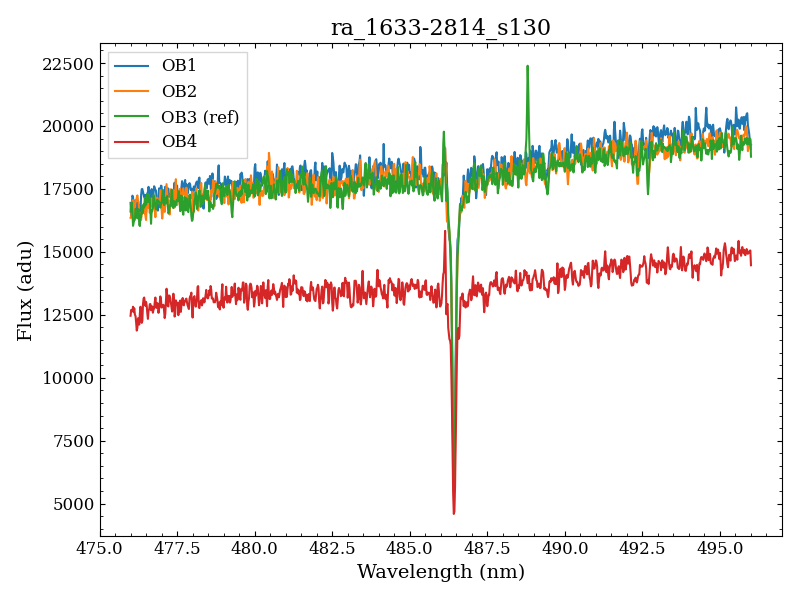

In [8]:
def cross_corr(star_df, minwave, maxwave, plot=False):
    """Using exposure with highest S/N, cross-correlating with all other exposures in star_df for a given wavelength region. Recommend strong absorption features.

    Parameters
    ----------
    star_df : pandas.DataFrame
        Dataframe containing all spectra for a given star.
    minwave : float
        Minimum wavelength for cross-correlation
    maxwave : float
        Maximum wavelength for cross-correlation
    plot : bool, optional
        To make test plots showing cross-correlation over sliced region for all exposures, by default False.

    Returns
    -------
    star_df : pandas.DataFrame
        Pandas dataframe containing spectral data alongside shifted spectra for all exposures.
    """

    # Selecting exposure with highest S/N to be the reference spectra
    star_id = star_df['star_id'].to_numpy()[0]
    
    ref_exp = star_df[star_df['snr'] == star_df['snr'].max()]
    ref_ob = ref_exp['ob'].to_numpy()[0]
    ref_wave = ref_exp['wave'].to_numpy()[0]
    ref_flux = ref_exp['flux'].to_numpy()[0]
        
    waveindex = np.where((ref_wave >= minwave) & (ref_wave <= maxwave))[0]
    ref_wavecut = ref_wave[waveindex]
    ref_fluxcut = ref_flux[waveindex]

    # Cross-correlating over each exposure in star_df
    dict_list = []
    for i, exp in star_df.iterrows():
        
        # Getting individual exposure
        exp_ob = exp['ob']
        exp_wave = exp['wave']
        exp_flux = exp['flux']
        exp_err = exp['flux_err']
        exp_weights = exp['flux_weights']
        
        # Cutting wavelengths to match reference for shifting
        exp_wavecut = exp_wave[waveindex]
        exp_fluxcut = exp_flux[waveindex]
        exp_errcut = exp_err[waveindex]
        exp_weightcut = exp_weights[waveindex]

        # Cross-correlating by taking peak absorption feature, then shifting to template
        peak_ref = np.argmin(ref_fluxcut)
        peak_exp = np.argmin(exp_fluxcut)
        manual_shift = peak_ref - peak_exp
        
        # Applying shift to whole spectra. If shift is 0, then will use original spectrum. Otherwise will shift using np.roll
        if manual_shift == 0:
            spec_shift = exp_flux
            spec_err_shift = exp_err
        else:
            spec_shift = np.roll(exp_flux, manual_shift)
            spec_err_shift = np.roll(exp_err, manual_shift)
           
        # Storing into dictionary
        ob_dict = dict(ob=exp_ob, shift=manual_shift, spec_shift=spec_shift, spec_err_shift=spec_err_shift)
        dict_list.append(ob_dict)
        
    # Storing data into pandas.DataFrame, then merging with star_df
    df_shift = pd.DataFrame(dict_list)
    star_df = pd.merge(star_df, df_shift, how='inner', on='ob')
    
    # Plotting results
    if plot:
        plt.figure(figsize=[8, 6])
        
        for i, exp in star_df.iterrows():
            exp_ob = exp['ob']
            exp_wavecut = exp['wave'][waveindex]
            exp_spec_shift = exp['spec_shift'][waveindex]
            
            if ref_ob == exp_ob:
                plt.plot(exp_wavecut, exp_spec_shift, label=exp['ob'] + ' (ref)')
            else:
                plt.plot(exp_wavecut, exp_spec_shift, label=exp['ob'])
        
        plt.legend(fancybox=False)
        plt.xlabel('Wavelength (nm)')
        plt.ylabel('Flux (adu)')
        plt.title(star_id)
        plt.tight_layout()

        plt.savefig(plot, dpi=300, transparent=False, facecolor='white')
    
    return star_df

# UVB - Cross-correlating over Hbeta region (476-496nm)
# VIS - Cross-correlating over Halpha region (647-667nm)
df_test3 = cross_corr(df_test, 476, 496, plot='/data/misfit/benlowe/xshooter/reduced_data/comb_spec/test.png')
df_test3

Removing cosmic rays using sigma clipping

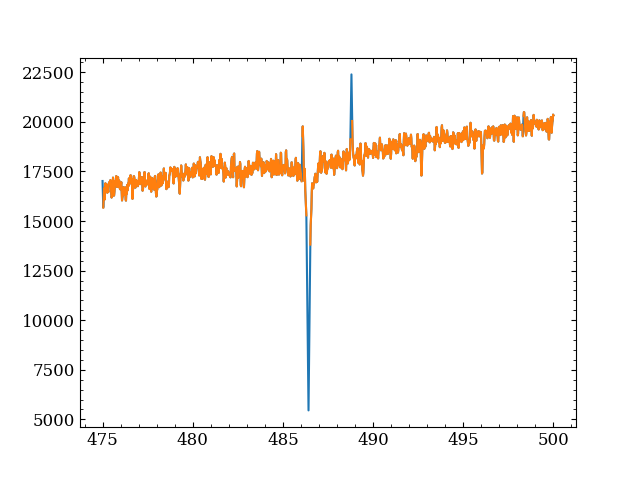

In [30]:
# Grabbing test region
test_ob3 = df_test3[df_test3['ob'] == 'OB3'][['wave', 'flux']]
test_wave = test_ob3['wave'].to_numpy()[0]
test_flux = test_ob3['flux'].to_numpy()[0]

wave_min = 475
wave_max = 500
wave_mask = (test_wave >= wave_min) & (test_wave <= wave_max)
test_wave = test_wave[wave_mask]
test_flux = test_flux[wave_mask]

deriv = np.diff(test_flux)
threshold = 3 * np.std(deriv)
spikes = np.where(np.abs(deriv) > threshold)[0]
test_flux[spikes] = np.nan
test_flux

# mask = np.ones_like(test_flux, dtype=bool)
# mask[spikes] = False
# interp_func = interp1d(test_wave[mask], test_flux[mask], kind='linear', fill_value="extrapolate")
# flux_clean = interp_func(test_wave)

plt.figure()
plt.plot(test_wave, flux_clean)
plt.plot(test_wave, test_flux)

In [90]:
# Grabbing test region
test_ob3 = df_test3[df_test3['ob'] == 'OB3'][['wave', 'flux']]
test_wave = test_ob3['wave'].to_numpy()[0]
test_flux = test_ob3['flux'].to_numpy()[0]

wave_min = 475
wave_max = 500
wave_mask = (test_wave >= wave_min) & (test_wave <= wave_max)
test_wave = test_wave[wave_mask]
test_flux = test_flux[wave_mask]

flux_clip = sigma_clip(data=test_flux, sigma_upper=3, sigma_lower=5)
clip_mask = test_flux[flux_clip.mask]
interp_func = interp1d(test_wave[flux_clip.mask], test_flux[flux_clip.mask], kind='linear', fill_value="extrapolate")
print(clip_mask)
# cleaned_flux = test_flux.copy()
# cleaned_flux[flux_clip.mask] = interp_func(test_wave[flux_clip.mask])
# cleaned_flux

plt.figure()
plt.plot(test_wave, test_flux, label='Original')
plt.plot(test_wave, cleaned_flux, label='Clipped')
# plt.xlabel('Wavelength (nm)')
# plt.ylabel('Flux')
# plt.legend()

IndexError: arrays used as indices must be of integer (or boolean) type

In [44]:
clip = test_flux[~test_ob3_clip.mask]


true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true
true


Stacking spectra using weighted averages

/home/benlowe/.local/lib/python3.9/site-packages/numpy/lib/function_base.py:553: RuntimeWarning: invalid value encountered in multiply
  avg = avg_as_array = np.multiply(a, wgt,


,ob,star_id,snr,wave,flux,flux_err,flux_weights,shift,spec_shift,spec_err_shift
0,OB1,ra_0834-5220_s316,107.051929,"[533.66, 533.68, 533.6999999999999, 533.719999...","[195058.109375, -260783.5, -292220.84375, -162...","[598264.625, 459240.4375, 403633.71875, 229644...","[2.7939160458828983e-12, 4.7415436829317635e-1...",0.0,"[195058.109375, -260783.5, -292220.84375, -162...","[598264.625, 459240.4375, 403633.71875, 229644..."
1,OB2,ra_0834-5220_s316,98.179814,"[533.66, 533.68, 533.6999999999999, 533.719999...","[-64326.140625, -1655069.625, -3347537.25, 195...","[126506048.0, 34731816.0, 72251696.0, 4080588....","[6.248523715750416e-17, 8.289818400225915e-16,...",0.0,"[-64326.140625, -1655069.625, -3347537.25, 195...","[126506048.0, 34731816.0, 72251696.0, 4080588...."
2,stack,ra_0834-5220_s316,145.256296,"[533.66, 533.68, 533.6999999999999, 533.719999...","[195052.30844052765, -261027.2256536178, -2923...","[598257.9350924772, 459200.2974004932, 403627....",NaN,NaN,NaN,NaN


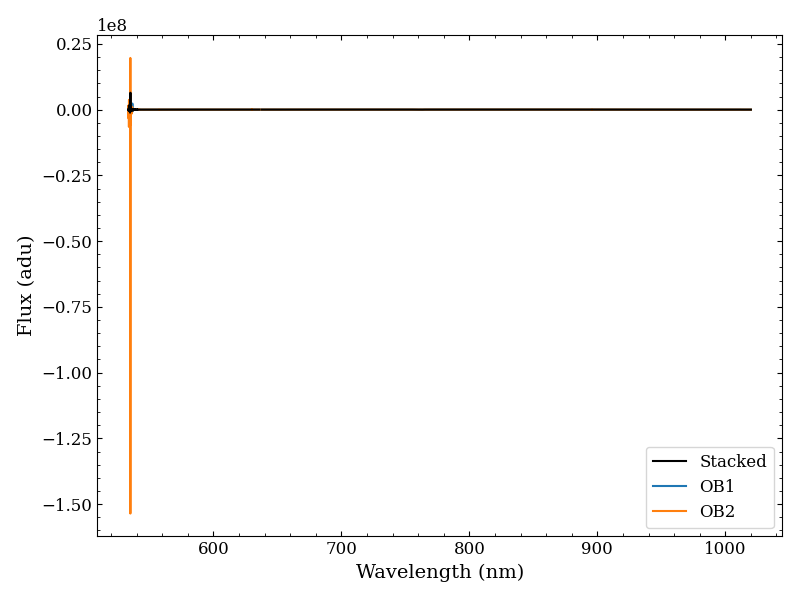

In [7]:
cstack_spec(star_df=df_test3, plot=True)

Correcting all spectra for radial velocity (NOT COMPLETE)

In [ ]:
def helio_calc(fits_path, star_df):
    """
    Calculates the barycentric velocity correction using the PyAstronomy helcorr function.

    Parameters
    ----------
    file : astropy.io.fits
        The .fits data product from the reduced file.
    star_ra : float
        Right asscension of star in degrees.
    star_dec : float
        Declination of star in degrees.

    Returns
    -------
    vel_corr : float
        Heliocentric velocity correction in Km/s
    """

    # Coordinates of observatory for Paranal Observatory, specifically UT3
    long_obs = file[0].header['LONG_OBS']
    lat_obs = file[0].header['LAT_OBS']
    alt_obs = file[0].header['ALT_OBS']

    # Julian Date
    mjd = file[0].header['UTMJD'] # Modified Julian Date (UTC)
    jd = mjd + 2400000.5

    # Calculating the heliocentric correction
    vel_corr, hjd = pyasl.helcorr(long_obs, lat_obs, alt_obs, star_ra, star_dec, jd)

    return vel_corr

rv_test = 143.22

### RV Shifting spectra

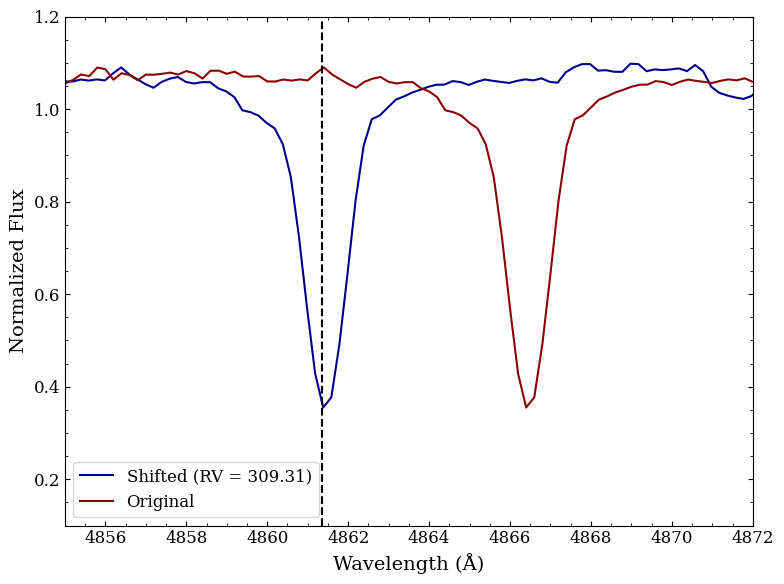

In [2]:
def rv_shift(waves, vel):
    """
    Performs radial shift on spectra.

    Parameters
    ----------
    waves : ndarray
        Wavelength array being shifted.

    vel : float
        Radial velocity value being used to perform the correction.

    Returns
    -------
    waves_shifted : ndarray
        Velocity-corrected wavelength array.
    """
    c = 299792.458

    # COMPUTING SHIFT IN LOG SPACE
    shift = np.log(1 + vel / c)

    # TRANSFORMING SHIFTED AXIS INTO WAVELENGTH SPACE
    waves_shifted = np.exp(np.log(waves) - shift)

    return waves_shifted


# Getting data
rv = 309.307416

uvb_fits = fits.open('/data/misfit/benlowe/xshooter/science_spec/ra_1752-4300_s6/uvb/ADP.2024-06-19T11:49:45.820.fits')[1].data
uvb_wave = uvb_fits['WAVE'][0] * 10 # Converting to Å
uvb_wave_shifted = rv_shift(waves=uvb_wave, vel=rv) 
uvb_flux = uvb_fits['FLUX_REDUCED'][0]

vis_fits = fits.open('/data/misfit/benlowe/xshooter/science_spec/ra_1752-4300_s6/vis/ADP.2024-06-19T11:49:45.824.fits')[1].data
vis_wave = vis_fits['WAVE'][0] * 10 # Converting to Å
vis_wave_shifted = rv_shift(waves=vis_wave, vel=rv)
vis_flux = vis_fits['FLUX_REDUCED'][0]

# plt.figure(figsize=[8,6])
# plt.plot(uvb_wave, uvb_flux/1e-15 - uvb_flux2/1e-15, color='black')
# plt.xlim(4800, 4900)
# plt.ylim(-0.2, 0.2)

# # Plotting shifted spectra
cont = np.mean(uvb_flux[(uvb_wave_shifted > 4850) & (uvb_wave_shifted < 4852) | (uvb_wave_shifted > 4565) & (uvb_wave_shifted < 4566)])
norm = uvb_flux/cont

plt.figure(figsize=[8, 6])
plt.plot(uvb_wave_shifted, norm, color='darkblue', label='Shifted (RV = {:.2f})'.format(rv))
plt.plot(uvb_wave, norm, color='darkred', label='Original')
plt.axvline(4861.35, color='black', linestyle='--')
plt.xlim(4855, 4872)
plt.ylim(0.1, 1.2)
plt.legend()
plt.xlabel("Wavelength (Å)")
plt.ylabel("Normalized Flux")
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/hbeta_rvshift.png', dpi=300, transparent=False, facecolor='white')

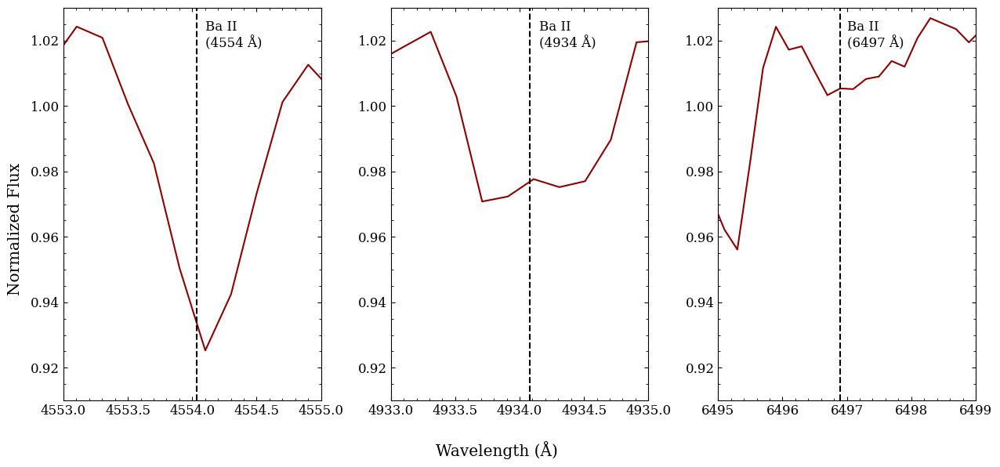

In [3]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=[13, 6])

# Ba II - 455.4034 nm
cont = np.mean(uvb_flux[(uvb_wave_shifted > 4542) & (uvb_wave_shifted < 4545) | (uvb_wave_shifted > 4565) & (uvb_wave_shifted < 4566)])
norm = uvb_flux/cont

ax1.plot(uvb_wave_shifted, norm, color='darkred')
ax1.axvline(4554.034, color='black', linestyle='--')
ax1.text(x=4554.1, y=1.018, s='Ba II\n(4554 Å)', fontsize=12)
ax1.set_xlim(4553, 4555)
ax1.set_ylim(0.91, 1.03)

# Ba II - 493.4077 nm
cont = np.mean(uvb_flux[(uvb_wave_shifted > 4915) & (uvb_wave_shifted < 4917)])
norm = uvb_flux/cont

ax2.plot(uvb_wave_shifted, norm, color='darkred')
ax2.axvline(4934.077, color='black', linestyle='--')
ax2.text(x=4934.15, y=1.018, s='Ba II\n(4934 Å)', fontsize=12)
ax2.set_xlim(4933, 4935)
ax2.set_ylim(0.91, 1.03)

# Ba II - 649.6897 nm
cont = np.mean(vis_flux[(vis_wave_shifted > 6485) & (vis_wave_shifted < 6490)])
norm = vis_flux/cont

ax3.plot(vis_wave_shifted, norm, color='darkred')
ax3.axvline(6496.897, color='black', linestyle='--')
ax3.text(x=6497, y=1.018, s='Ba II\n(6497 Å)', fontsize=12)
ax3.set_xlim(6495, 6499)
ax3.set_ylim(0.91, 1.03)


fig.supylabel('Normalized Flux')
fig.supxlabel('Wavelength (Å)')

plt.tight_layout()
plt.savefig('ba_tests.png', dpi=300, transparent=False, facecolor='white')

Loading in data

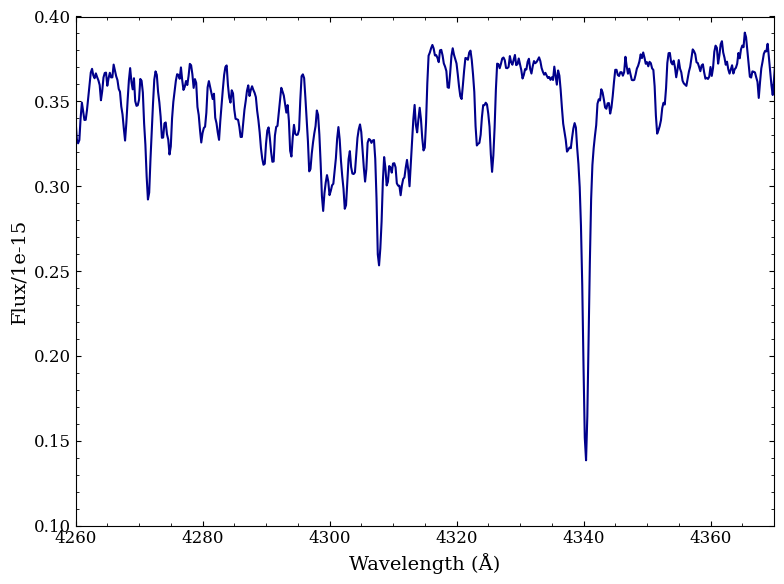

In [43]:
# Getting NIR data for a given star
star_dir = '/data/misfit/benlowe/xshooter/science_spec/ra_1752-4300_s269/uvb/'
nir_fits = [nir for nir in os.listdir(star_dir) if nir[-4:] == 'fits']

flux_list = []
for file in nir_fits:
    flux = fits.open(star_dir + file)[1].data['FLUX'][0]
    flux_list.append(flux)
wave = fits.open(star_dir + file)[1].data['WAVE'][0]

# Stacking
data_stack = np.sum(flux_list, axis=0)/len(flux_list)

# Plotting
plt.figure(figsize=[8, 6])
plt.plot(wave*10, data_stack/1e-15, color='darkblue')
plt.xlim(4260, 4370)
plt.ylim(0.1, 0.4)
plt.xlabel("Wavelength (Å)")
plt.ylabel("Flux/1e-15")
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/sep10/ra_1752-4300_s269.png', dpi=300, transparent=False, facecolor='white', bbox_inches='tight')

Determining S/N for stacked spectra

In [15]:
n_spec = 14
sn_list = np.array([9.78, 9.65, 9.59, 9.27, 9.25, 9.66, 9.68, 11.33, 11.34, 11.24, 11.38, 11.39, 11.37, 11.25])
sn_final = np.sqrt(np.sum(sn_list**2))
sn_final

39.2126306182077